
# Data Loading and Initial Inspection



In [17]:

# ============================================================
# H1N1 Vaccine Prediction Challenge - Dataset B
# ============================================================

# Import Pandas
import pandas as pd

# ------------------------------------------------------------
# 1. Load the datasets
# ------------------------------------------------------------

# Training dataset: includes known H1N1 vaccination outcomes
train_df = pd.read_csv("dataset_B_training.csv")

# Testing dataset: vaccination outcomes must be predicted
test_df = pd.read_csv("dataset_B_testing.csv")

# Example submission: defines the required prediction format
submission_df = pd.read_csv(
    "dataset_B_example_submission.csv"
)

print("All datasets loaded successfully!")

# ------------------------------------------------------------
# 2. Check dataset dimensions
# ------------------------------------------------------------

print("\nTRAINING DATASET:", train_df.shape)
print("TESTING DATASET:", test_df.shape)
print("SUBMISSION TEMPLATE:", submission_df.shape)

# ------------------------------------------------------------
# 3. Display the first five rows
# ------------------------------------------------------------

print("\nTraining dataset:")
display(train_df.head())

#  print("\nTesting dataset:")
#  display(test_df.head())

print("\nExample submission:")
display(submission_df.head())

# ------------------------------------------------------------
# 4. Examine column names and data types
# ------------------------------------------------------------

# print("\nTraining dataset information:")
# train_df.info()

# ------------------------------------------------------------
# 5. Verify the target variable
# ------------------------------------------------------------

target = "h1n1_vaccine"

assert target in train_df.columns, (
    "Target column is missing from the training dataset."
)

assert target not in test_df.columns, (
    "The testing dataset should not contain the target."
)

# Check that training and testing predictors match
train_features = set(train_df.columns) - {target}
test_features = set(test_df.columns)

assert train_features == test_features, (
    "Training and testing feature columns do not match."
)

# Verify that submission IDs match test IDs
assert submission_df["respondent_id"].equals(
    test_df["respondent_id"]
), "Submission respondent IDs do not match the test dataset."

#  print("\nDataset structure verified successfully!")


All datasets loaded successfully!

TRAINING DATASET: (4756, 31)
TESTING DATASET: (4749, 30)
SUBMISSION TEMPLATE: (4749, 2)

Training dataset:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0



Example submission:


,respondent_id,h1n1_vaccine
0,4757,0.0
1,4758,0.0
2,4759,0.0
3,4760,0.0
4,4761,0.0


## Conclusion
The datasets have been loaded and their structures checked.
The next stage is Exploratory Data Analysis (EDA), which will
investigate missing values, feature distributions, and
relationships with vaccination outcomes.


Exploratory Data Analysis (EDA)


Exploratory Data Analysis (EDA)


H1N1 Vaccination Distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Vaccination Percentages:
h1n1_vaccine
0    60.6
1    39.4
Name: proportion, dtype: float64


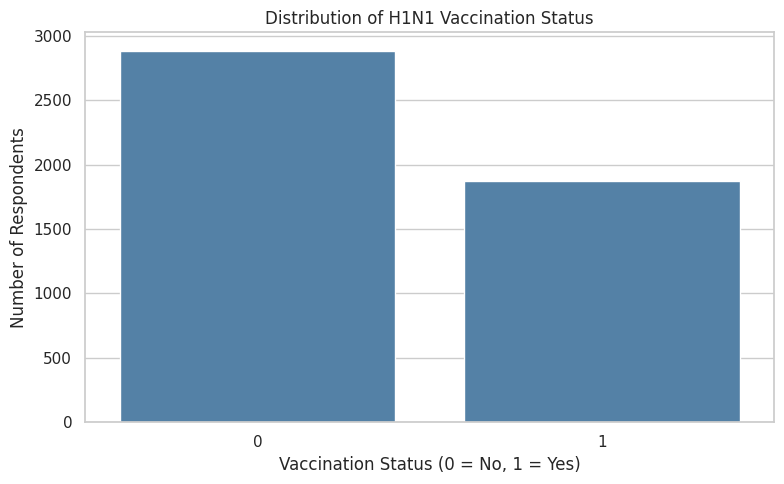


Missing Values (%):
employment_sector                49.71
health_insurance                 40.48
income_poverty                   14.97
doctor_recc_h1n1                  6.71
rent_or_own                       6.62
employment_status                 4.94
marital_status                    4.75
education                         4.71
child_under_6_months              2.82
health_worker                     2.75
opinion_h1n1_vacc_effective       1.45
opinion_h1n1_risk                 1.35
opinion_h1n1_sick_from_vacc       1.35
household_adults                  0.71
household_children                0.71
behavioral_avoidance              0.57
h1n1_knowledge                    0.46
behavioral_touch_face             0.42
behavioral_antiviral_meds         0.36
h1n1_concern                      0.32
behavioral_outside_home           0.32
behavioral_large_gatherings       0.19
behavioral_wash_hands             0.17
behavioral_face_mask              0.08
respondent_id                     0.00
age_

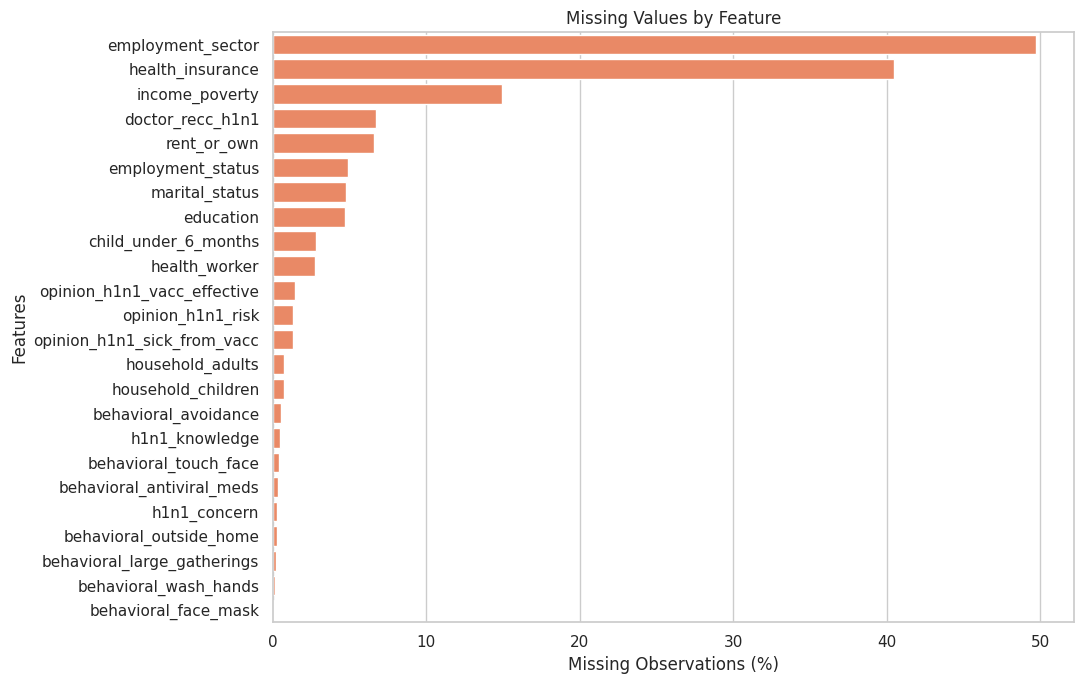


Vaccination Rates by Age Group:


,mean,count,vaccination_rate
age_group,,,
18 - 34 Years,0.36,894,36.47
35 - 44 Years,0.40,659,39.61
45 - 54 Years,0.37,913,36.58
55 - 64 Years,0.42,1065,41.88
65+ Years,0.41,1225,41.39


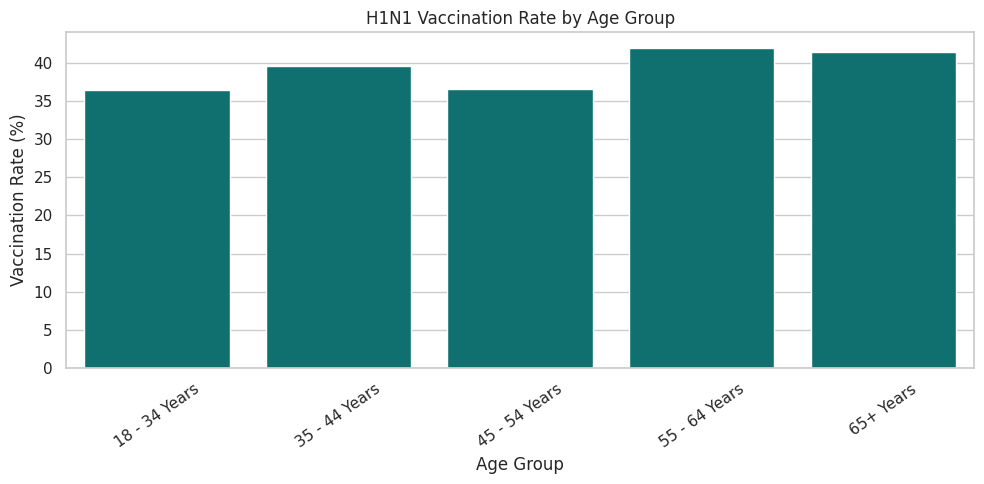


EDA Part 1 completed successfully!


In [18]:

# ============================================================
# EXPLORATORY DATA ANALYSIS (EDA)
# Dataset B - H1N1 Vaccine Prediction Challenge
# ============================================================

# Import libraries for numerical analysis and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style for presentation figures
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. Analyse the target variable
# ------------------------------------------------------------

# Calculate vaccination class counts and percentages
target_counts = train_df["h1n1_vaccine"].value_counts()
target_percentages = (
    train_df["h1n1_vaccine"].value_counts(normalize=True) * 100
)

print("H1N1 Vaccination Distribution:")
print(target_counts)
print("\nVaccination Percentages:")
print(target_percentages.round(2))

# Visualise the class distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="h1n1_vaccine",
    order=[0, 1],
    color="steelblue"
)

plt.title("Distribution of H1N1 Vaccination Status")
plt.xlabel("Vaccination Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Investigate missing values
# ------------------------------------------------------------

# Calculate the percentage of missing observations
missing_percentage = (
    train_df.isnull().mean() * 100
).sort_values(ascending=False)

print("\nMissing Values (%):")
print(missing_percentage.round(2))

# Display features containing missing values
missing_features = missing_percentage[
    missing_percentage > 0
]

plt.figure(figsize=(11, 7))

sns.barplot(
    x=missing_features.values,
    y=missing_features.index,
    color="coral"
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Observations (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Explore vaccination rates by age group
# ------------------------------------------------------------

# Calculate average vaccination rate for each age group
age_vaccination = (
    train_df.groupby("age_group")["h1n1_vaccine"]
    .agg(["mean", "count"])
    .sort_index()
)

# Convert the vaccination rate into a percentage
age_vaccination["vaccination_rate"] = (
    age_vaccination["mean"] * 100
)

print("\nVaccination Rates by Age Group:")
display(age_vaccination.round(2))

# Visualise the age-group vaccination rates
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_vaccination.reset_index(),
    x="age_group",
    y="vaccination_rate",
    color="teal"
)

plt.title("H1N1 Vaccination Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Vaccination Rate (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("\nEDA Part 1 completed successfully!")



## Initial Findings and Critical Analysis

### Target Distribution
The dataset contains 4,756 training observations.

- 2,882 respondents (60.6%) were not vaccinated.
- 1,874 respondents (39.4%) were vaccinated.

The target variable exhibits moderate class imbalance.
Therefore, accuracy alone may not be sufficient to
evaluate model performance.

Stratified validation, ROC-AUC, probability calibration,
and the challenge-specific financial cost metric will
be investigated.

### Missing Data
Several features contain missing observations, particularly
employment_sector and health_insurance.

Deleting incomplete rows could substantially reduce the
available training data and introduce selection bias.

We will compare appropriate imputation strategies during
preprocessing and evaluate their impact on model performance.

### Age-Related Vaccination Patterns
Vaccination rates have been calculated across age groups.

Differences observed between groups may provide useful
predictive information, but they should not be interpreted
as evidence of causation.

### Implications for Modelling
The EDA findings indicate that our modelling pipeline
should include:

- Appropriate numerical and categorical imputation.
- Encoding of categorical variables.
- Stratified training and validation splits.
- Comparison of multiple machine learning algorithms.
- Evaluation using the task-specific financial cost metric.


Advanced Exploratory Data Analysis (EDA)


# Advanced Exploratory Data Analysis


Vaccination rates by doctor's recommendation:


,mean,count,vaccination_rate
doctor_status,,,
Missing,0.18,319,18.18
Not recommended,0.28,3149,27.91
Recommended,0.73,1288,72.75


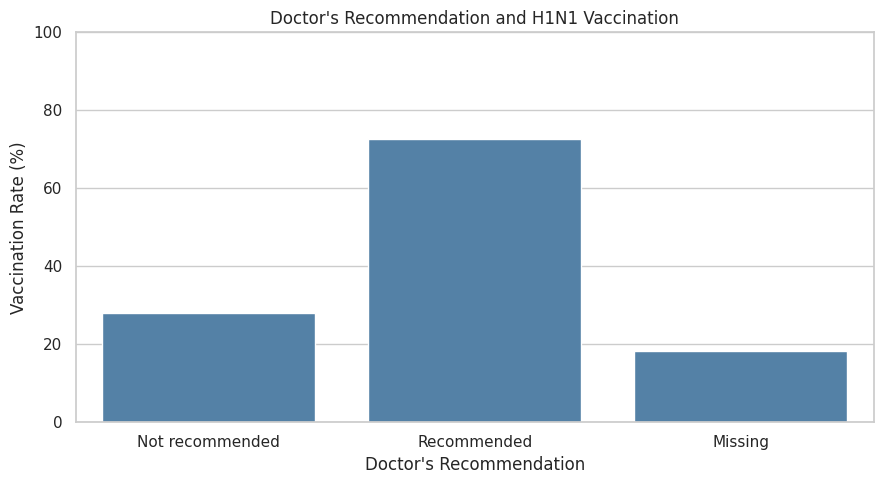

Vaccination rates by perceived vaccine effectiveness:


,mean,count,vaccination_rate
opinion_h1n1_vacc_effective,,,
1.0,0.11,139,10.79
2.0,0.13,260,12.69
3.0,0.22,728,22.25
4.0,0.34,2057,33.93
5.0,0.63,1503,62.54


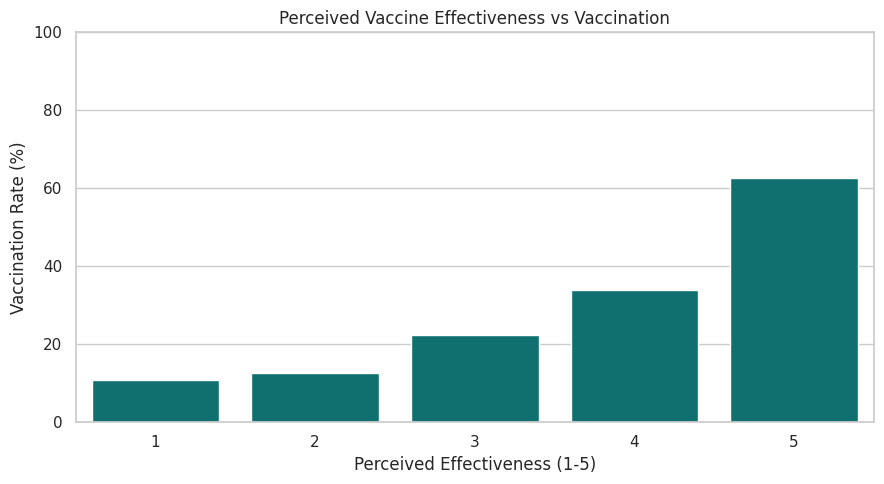

Vaccination rates by perceived infection risk:


,mean,count,vaccination_rate
opinion_h1n1_risk,,,
1.0,0.20,1274,19.86
2.0,0.32,1683,32.38
3.0,0.36,178,35.96
4.0,0.61,1171,61.06
5.0,0.70,386,70.47


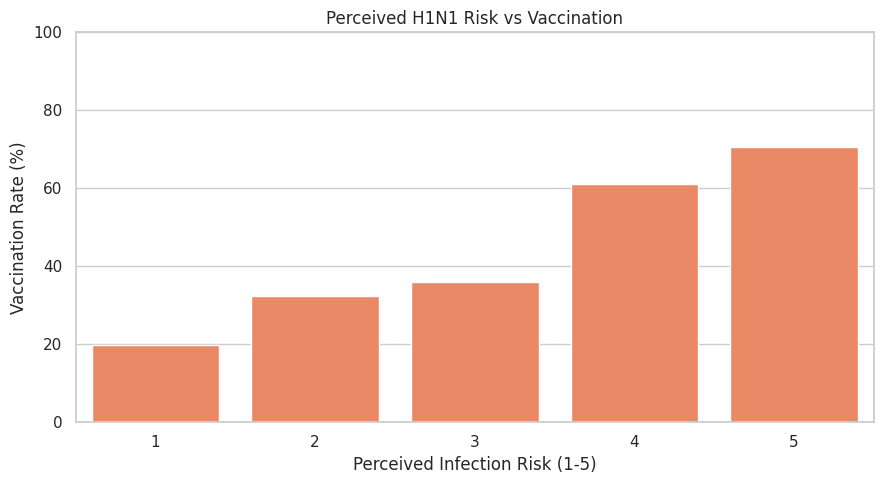

Vaccination rates by chronic medical conditions:


,mean,count,vaccination_rate
chronic_group,,,
0,0.36,3313,35.98
1,0.46,1114,45.60
2,0.51,255,51.37
3+,0.58,74,58.11


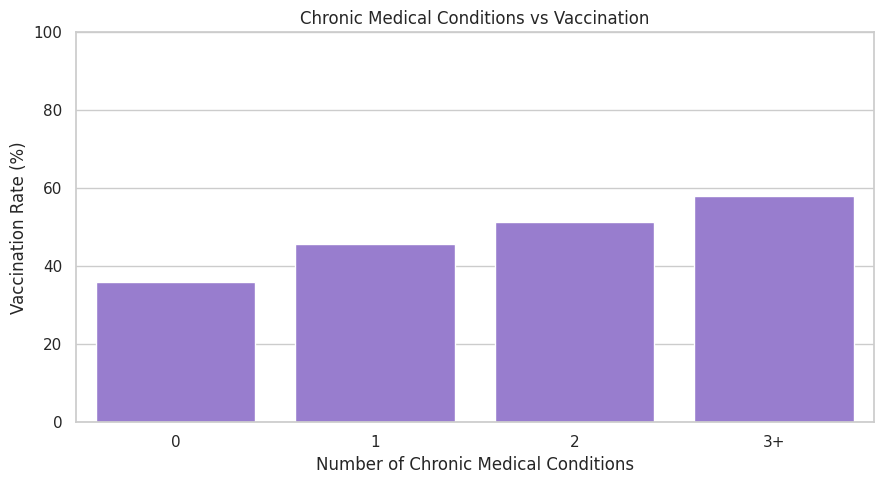

Top 10 numerical associations with vaccination:


,h1n1_vaccine
doctor_recc_h1n1,0.414
opinion_h1n1_risk,0.355
opinion_h1n1_vacc_effective,0.347
health_worker,0.205
h1n1_knowledge,0.151
h1n1_concern,0.145
health_insurance,0.129
number_chronic_med_conditions,0.110
behavioral_touch_face,0.103
behavioral_wash_hands,0.093


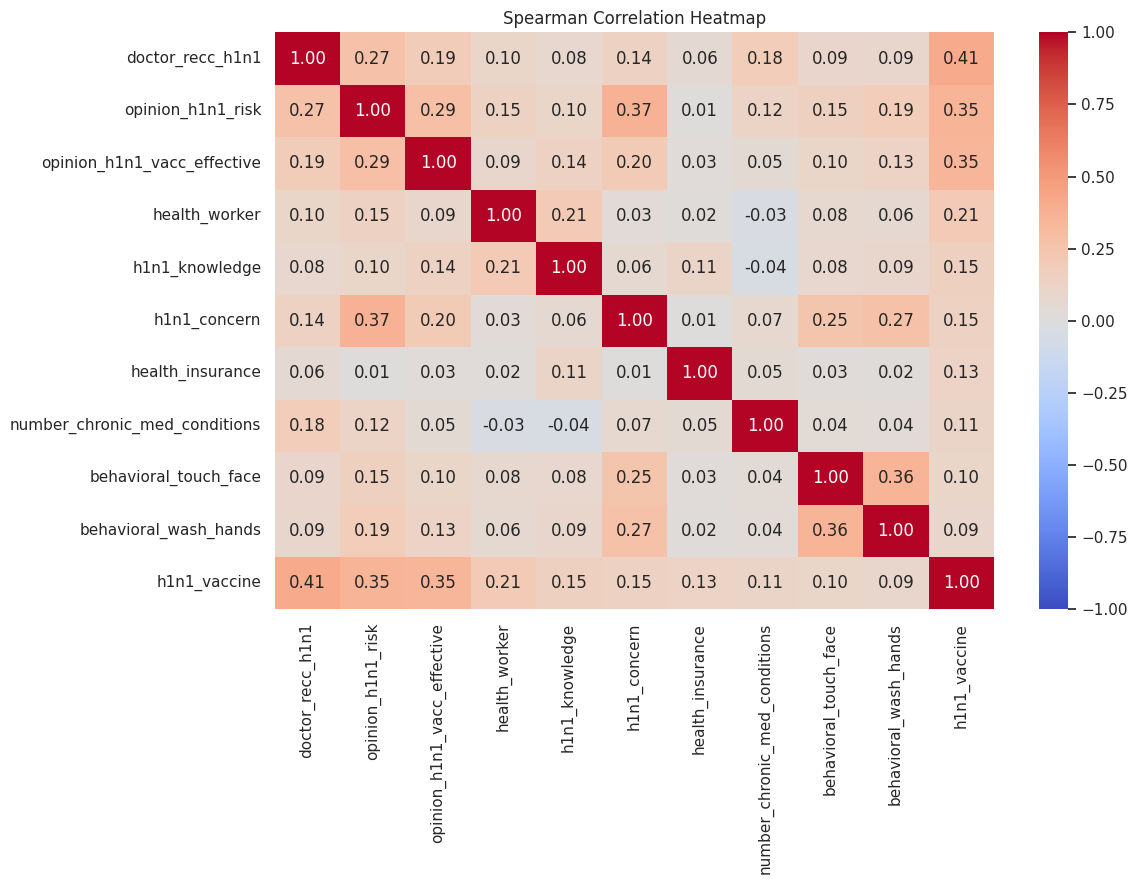

In [34]:

# ============================================================
# ADVANCED EXPLORATORY DATA ANALYSIS
# H1N1 Vaccine Prediction Challenge - Dataset B
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. Doctor's recommendation vs vaccination
# ------------------------------------------------------------

# Create a copy to preserve the original training data
eda_df = train_df.copy()

# Assign understandable labels, including missing responses
eda_df["doctor_status"] = (
    eda_df["doctor_recc_h1n1"]
    .map({0: "Not recommended", 1: "Recommended"})
    .fillna("Missing")
)

# Calculate vaccination rates and group sizes
doctor_analysis = (
    eda_df.groupby("doctor_status")["h1n1_vaccine"]
    .agg(["mean", "count"])
)

doctor_analysis["vaccination_rate"] = (
    doctor_analysis["mean"] * 100
)

print("Vaccination rates by doctor's recommendation:")
display(doctor_analysis.round(2))

# Plot vaccination rates
plt.figure(figsize=(9, 5))

sns.barplot(
    data=doctor_analysis.reset_index(),
    x="doctor_status",
    y="vaccination_rate",
    order=["Not recommended", "Recommended", "Missing"],
    color="steelblue"
)

plt.title("Doctor's Recommendation and H1N1 Vaccination")
plt.xlabel("Doctor's Recommendation")
plt.ylabel("Vaccination Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Opinion about vaccine effectiveness
# ------------------------------------------------------------

# 1 = Not at all effective, 5 = Very effective
# 3 = Don't know (a valid response category)

effectiveness = (
    eda_df.groupby("opinion_h1n1_vacc_effective")
    ["h1n1_vaccine"]
    .agg(["mean", "count"])
    .dropna()
)

effectiveness["vaccination_rate"] = (
    effectiveness["mean"] * 100
)

print("Vaccination rates by perceived vaccine effectiveness:")
display(effectiveness.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=effectiveness.index.astype(int).astype(str),
    y=effectiveness["vaccination_rate"],
    color="teal"
)

plt.title("Perceived Vaccine Effectiveness vs Vaccination")
plt.xlabel("Perceived Effectiveness (1-5)")
plt.ylabel("Vaccination Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Perceived H1N1 infection risk
# ------------------------------------------------------------

risk_analysis = (
    eda_df.groupby("opinion_h1n1_risk")
    ["h1n1_vaccine"]
    .agg(["mean", "count"])
    .dropna()
)

risk_analysis["vaccination_rate"] = (
    risk_analysis["mean"] * 100
)

print("Vaccination rates by perceived infection risk:")
display(risk_analysis.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_analysis.index.astype(int).astype(str),
    y=risk_analysis["vaccination_rate"],
    color="coral"
)

plt.title("Perceived H1N1 Risk vs Vaccination")
plt.xlabel("Perceived Infection Risk (1-5)")
plt.ylabel("Vaccination Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Chronic medical conditions and vaccination
# ------------------------------------------------------------

# Group 3 or more conditions together because these
# categories have relatively few respondents
eda_df["chronic_group"] = pd.cut(
    eda_df["number_chronic_med_conditions"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)

chronic_analysis = (
    eda_df.groupby(
        "chronic_group", observed=True
    )["h1n1_vaccine"]
    .agg(["mean", "count"])
)

chronic_analysis["vaccination_rate"] = (
    chronic_analysis["mean"] * 100
)

print("Vaccination rates by chronic medical conditions:")
display(chronic_analysis.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=chronic_analysis.index.astype(str),
    y=chronic_analysis["vaccination_rate"],
    color="mediumpurple"
)

plt.title("Chronic Medical Conditions vs Vaccination")
plt.xlabel("Number of Chronic Medical Conditions")
plt.ylabel("Vaccination Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Spearman correlation analysis
# ------------------------------------------------------------

# Select numerical variables and remove respondent_id,
# which is an identifier rather than a predictive feature
numeric_df = train_df.select_dtypes(
    include="number"
).drop(columns=["respondent_id"])

# Spearman correlation assesses monotonic relationships
correlation_matrix = numeric_df.corr(method="spearman")

# Find the strongest numerical associations with the target
target_correlations = (
    correlation_matrix["h1n1_vaccine"]
    .drop("h1n1_vaccine")
    .sort_values(key=abs, ascending=False)
)

print("Top 10 numerical associations with vaccination:")
display(target_correlations.head(10).round(3))

# Select the strongest associated features for a heatmap
top_features = (
    target_correlations.head(10).index.tolist()
)

selected_features = top_features + ["h1n1_vaccine"]

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix.loc[
        selected_features, selected_features
    ],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

# print("\nAdvanced EDA completed successfully!")



## Findings and Critical Analysis

### Doctor's Recommendation

Respondents receiving a doctor's recommendation had
a substantially higher vaccination rate (72.7%) than
those without a recommendation (27.9%).

This suggests that doctor's recommendations could be
a useful predictor of H1N1 vaccination behaviour.

However, the relationship is observational and does
not prove that recommendations caused vaccination.

### Perceived Vaccine Effectiveness

Vaccination uptake was approximately 62.5% among
respondents who believed the vaccine was very effective,
compared with 10.8% among respondents who believed
it was not at all effective.

This indicates a strong association between vaccine
attitudes and observed vaccination outcomes.

### Perceived Infection Risk

Higher perceived infection risk was generally associated
with higher vaccination rates.

Perceived risk may therefore provide useful predictive
information about vaccination decisions.

### Chronic Medical Conditions

Vaccination rates generally increased with the number
of reported chronic conditions.

However, groups with multiple chronic conditions
contained relatively few respondents. Their estimated
vaccination rates may therefore be less reliable.

### Correlation Analysis

Spearman correlation identified several potentially
important predictors, including:

- Doctor's recommendation
- Perceived H1N1 infection risk
- Perceived vaccine effectiveness
- Healthcare worker status

These findings are exploratory. Correlation does not
measure causal influence, and associations may be
affected by other variables.

Furthermore, some ordinal survey variables include
"Don't know" as a coded response, so their numeric
correlations require careful interpretation.

## Implications for Machine Learning

The analysis suggests that vaccine attitudes,
health-related characteristics, and recommendations
may contain useful predictive information.

We will retain these features for initial model
comparison rather than selecting features solely
using their individual correlations.

Further modelling will investigate whether these
relationships improve generalisation to unseen data.

All model fitting and preprocessing decisions will
be evaluated using training-only cross-validation
to avoid data leakage.


Data Preprocessing and Preparation for Machine Learning

In [35]:

# ============================================================
# DATA PREPROCESSING
# Dataset B - H1N1 Vaccine Prediction Challenge
# ============================================================

# Import required libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

# ------------------------------------------------------------
# 1. Separate features and target
# ------------------------------------------------------------

# Target variable: observed H1N1 vaccination status
target = "h1n1_vaccine"

# Exclude the target and respondent identifier
feature_columns = [
    col for col in train_df.columns
    if col not in ["respondent_id", target]
]

# Input features for model development
X = train_df[feature_columns].copy()

# Known vaccination outcomes
y = train_df[target].copy()

# Hidden-test features, kept separate
X_test = test_df[feature_columns].copy()

print("Original feature shape:", X.shape)
print("Target shape:", y.shape)
print("Hidden test shape:", X_test.shape)


# ------------------------------------------------------------
# 2. Treat vaccine-opinion variables as categorical
# ------------------------------------------------------------

# The value 3 means "Don't know", not a numeric midpoint.
# We therefore represent these responses as categories.

opinion_columns = [
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc"
]

# Apply the same deterministic conversion to both datasets
for dataframe in [X, X_test]:

    for col in opinion_columns:

        dataframe[col] = dataframe[col].map(
            lambda value: str(int(value))
            if pd.notna(value) else np.nan
        )


# ------------------------------------------------------------
# 3. Identify feature types
# ------------------------------------------------------------

# Identify binary features from the dataset values
binary_columns = [
    col for col in X.columns
    if pd.api.types.is_numeric_dtype(X[col])
    and X[col].notna().any()
    and set(X[col].dropna().unique()).issubset({0, 1})
]

# Other numeric features: counts and ordinal measures
numeric_columns = [
    col for col in X.select_dtypes(
        include="number"
    ).columns
    if col not in binary_columns
]

# Categorical features, including vaccine opinions
categorical_columns = X.select_dtypes(
    exclude="number"
).columns.tolist()

print("\nBinary features:", len(binary_columns))
print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))


# ------------------------------------------------------------
# 4. Split into training and validation data
# ------------------------------------------------------------

# Stratification preserves the target-class distribution
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))

print(
    "Training vaccination rate:",
    round(y_train.mean() * 100, 2), "%"
)

print(
    "Validation vaccination rate:",
    round(y_val.mean() * 100, 2), "%"
)


# ------------------------------------------------------------
# 5. Create numerical preprocessing pipeline
# ------------------------------------------------------------

numeric_pipeline = Pipeline(steps=[

    # Replace missing values using the training median
    # Add missingness indicators where applicable
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),

    # Standardise numerical features
    (
        "scaler",
        StandardScaler()
    )

])


# ------------------------------------------------------------
# 6. Create binary preprocessing pipeline
# ------------------------------------------------------------

binary_pipeline = Pipeline(steps=[

    # Replace missing binary values with the most
    # frequent observed class
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent",
            add_indicator=True
        )
    )

])


# ------------------------------------------------------------
# 7. Create categorical preprocessing pipeline
# ------------------------------------------------------------

categorical_pipeline = Pipeline(steps=[

    # Preserve missing categorical responses as a category
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),

    # Convert categorical responses into encoded features
    # Ignore previously unseen categories during prediction
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )

])


# ------------------------------------------------------------
# 8. Combine the preprocessing pipelines
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[

        (
            "numerical",
            numeric_pipeline,
            numeric_columns
        ),

        (
            "binary",
            binary_pipeline,
            binary_columns
        ),

        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )

    ]
)


# ------------------------------------------------------------
# 9. Fit preprocessing using training data only
# ------------------------------------------------------------

# Learn imputation, encoding and scaling parameters
# exclusively from the training subset
X_train_processed = preprocessor.fit_transform(
    X_train
)

# Apply the identical learned transformations
# to validation data without fitting again
X_val_processed = preprocessor.transform(
    X_val
)


# ------------------------------------------------------------
# 10. Verify processed dataset dimensions
# ------------------------------------------------------------

print("\nPREPROCESSING RESULTS")

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed validation shape:",
    X_val_processed.shape
)

# Check that the processed feature dimensions match
assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
), "Feature dimension mismatch!"

# print("\nPreprocessing completed successfully!")
# print("Training and validation features are ready.")


Original feature shape: (4756, 29)
Target shape: (4756,)
Hidden test shape: (4749, 29)

Binary features: 11
Numerical features: 5
Categorical features: 13

Training rows: 3804
Validation rows: 952
Training vaccination rate: 39.41 %
Validation vaccination rate: 39.39 %

PREPROCESSING RESULTS
Processed training shape: (3804, 103)
Processed validation shape: (952, 103)



## Critical Analysis of Preprocessing

### Missing Value Imputation

Missing data were handled using strategies appropriate
to each feature type rather than deleting incomplete rows.

Median imputation was selected for numerical variables
because it is relatively robust to extreme values.

The most frequent category was used to impute binary
variables, while missing categorical responses were
preserved as a separate category.

Missingness indicators were also introduced for
numerical and binary features where appropriate.

These decisions preserve observations but introduce
assumptions about missing values.

For example, mode imputation may overrepresent the
majority category, while a "Missing" category does
not explain why responses are absent.

Alternative imputation methods should therefore be
evaluated during model comparison.

### Categorical Encoding

One-Hot Encoding was selected to represent categories
without introducing artificial ordering.

Vaccine-opinion responses were treated as categorical
because the response "Don't know" is not necessarily
between positive and negative beliefs.

A limitation is that One-Hot Encoding increases
feature dimensionality and can create sparse data.

### Feature Scaling

StandardScaler was applied to numerical features,
making them more comparable in magnitude.

This is particularly useful for distance-based and
regularised linear models.

Tree-based models generally do not require scaling,
so its effect will be investigated during comparison.

### Stratified Validation

An 80/20 stratified split was used to preserve the
vaccination class distribution.

The fixed random state supports reproducibility.

However, a single validation split may be sensitive
to random variation.

Stratified cross-validation will therefore be used
in subsequent modelling experiments.

### Data Leakage Prevention

Preprocessing parameters were fitted using only
the training subset.

Validation data were transformed using these
previously learned parameters.

This prevents information from the validation set
from influencing the training transformations.

### Future Improvements

We will compare:

1. Different machine learning algorithms.
2. Alternative imputation strategies.
3. Alternative feature representations.
4. Hyperparameter configurations.
5. Cross-validation performance and variability.

The final model will be selected primarily using
the task-specific financial cost metric rather than
classification accuracy alone.


Train and Compare Machine Learning Models


# Machine Learning Model Development

## Objective

This stage develops and compares multiple supervised
machine learning algorithms to predict H1N1 vaccination
acceptance.

The target variable is `h1n1_vaccine`:

- 0 = Respondent did not receive the H1N1 vaccine
- 1 = Respondent received the H1N1 vaccine

## Selected Algorithms

### Logistic Regression

Logistic Regression is used as an interpretable baseline
for binary classification.

Advantages:
- Computationally efficient
- Produces predicted probabilities
- Supports interpretation of feature coefficients

Limitations:
- Assumes a linear relationship in log-odds
- May not capture complex nonlinear interactions

### Random Forest

Random Forest combines multiple decision trees to
produce robust predictions.

Advantages:
- Captures nonlinear relationships
- Models complex feature interactions
- Less sensitive to feature scaling

Limitations:
- Less interpretable than Logistic Regression
- Can be computationally expensive
- Probability estimates may require calibration

### Gradient Boosting

Gradient Boosting builds decision trees sequentially
to reduce prediction errors.

Advantages:
- Captures complex nonlinear patterns
- Often performs well on structured datasets
- Supports flexible model optimisation

Limitations:
- Sensitive to hyperparameter choices
- May overfit without suitable regularisation
- Requires careful performance evaluation

##  Evaluation Strategy

We use five-fold stratified cross-validation on the
training subset, followed by evaluation on a separate
20% holdout validation subset.

Evaluation measures include:

1. Accuracy
2. ROC-AUC
3. Brier score
4. Confusion matrix

The Brier score measures the quality of probability
predictions, with lower values indicating better results.

Preprocessing is included inside each model pipeline,
ensuring that validation fold information is not used
when learning preprocessing parameters.

These metrics provide initial performance evidence.
Final model selection will consider the challenge-specific
financial cost of vaccination, compensation and
hospitalisation.



TRAINING: Logistic Regression
Validation Accuracy: 0.7710
Validation ROC-AUC:  0.8372
Validation Brier:    0.1565

TRAINING: Random Forest
Validation Accuracy: 0.7616
Validation ROC-AUC:  0.8284
Validation Brier:    0.1632

TRAINING: Gradient Boosting
Validation Accuracy: 0.7794
Validation ROC-AUC:  0.8426
Validation Brier:    0.1542

FIVE-FOLD CROSS-VALIDATION RESULTS


,Model,CV Accuracy,CV ROC-AUC,CV AUC SD,CV Brier
0,Logistic Regression,0.7857,0.8537,0.0098,0.1481
1,Random Forest,0.7900,0.8551,0.0109,0.1519
2,Gradient Boosting,0.7897,0.8531,0.0109,0.1477



HOLDOUT VALIDATION RESULTS


,Model,Accuracy,ROC-AUC,Brier Score
0,Gradient Boosting,0.7794,0.8426,0.1542
1,Logistic Regression,0.7710,0.8372,0.1565
2,Random Forest,0.7616,0.8284,0.1632


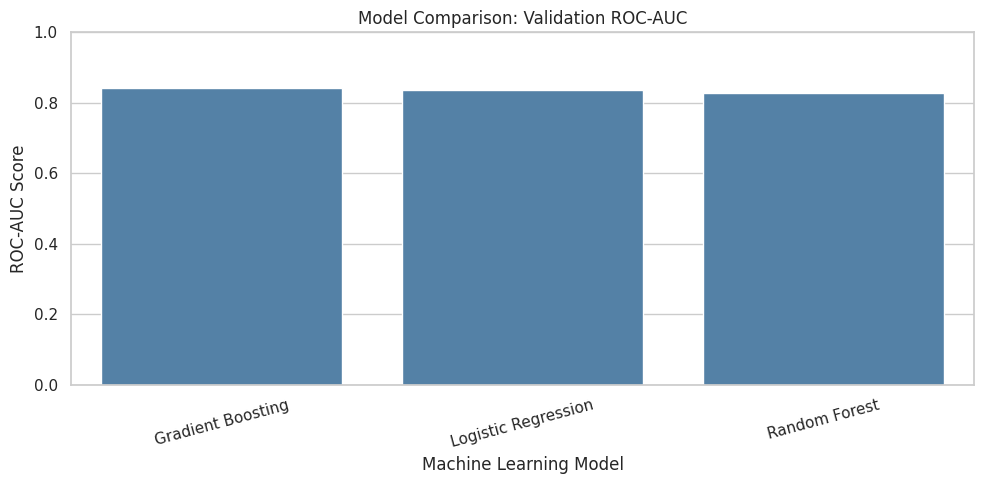


Preliminary ROC-AUC leader:
Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.82       577
           1       0.75      0.66      0.70       375

    accuracy                           0.78       952
   macro avg       0.77      0.76      0.76       952
weighted avg       0.78      0.78      0.78       952



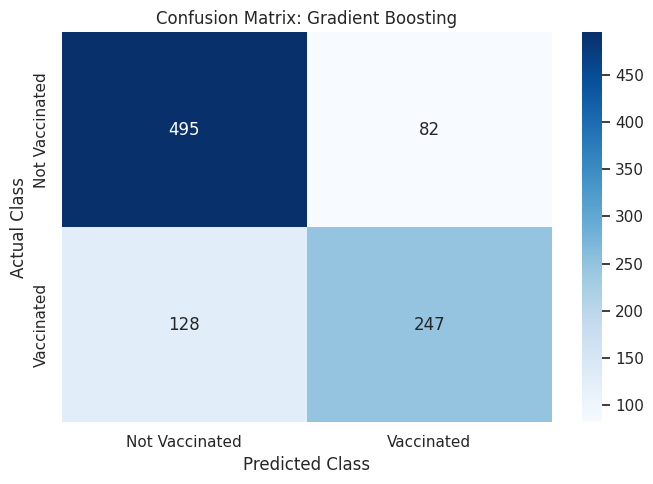

In [36]:

# ============================================================
# MACHINE LEARNING MODEL COMPARISON
# H1N1 Vaccine Prediction Challenge - Dataset B
# ============================================================

# ------------------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 2. Define the machine learning algorithms
# ------------------------------------------------------------

# All models use a fixed random state for reproducibility

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        C=1.0,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.08,
        max_depth=3,
        random_state=42
    )
}

# ------------------------------------------------------------
# 3. Configure stratified cross-validation
# ------------------------------------------------------------

# The training subset is divided into five folds.
# Preprocessing will be fitted separately within each fold.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define multiple evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "brier": "neg_brier_score"
}

# ------------------------------------------------------------
# 4. Train and evaluate each algorithm
# ------------------------------------------------------------

cv_results = []
validation_results = []

# Store fitted models and probabilities for later steps
trained_models = {}
validation_probs = {}

for name, classifier in models.items():

    print("\n" + "=" * 55)
    print("TRAINING:", name)
    print("=" * 55)

    # Include preprocessing inside the model pipeline.
    # clone() creates a fresh, unfitted preprocessor.
    pipeline = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    # --------------------------------------------------------
    # A. Perform five-fold cross-validation
    # --------------------------------------------------------

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    # Record average scores and variation across folds
    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV AUC SD": scores["test_roc_auc"].std(),
        "CV Brier": -scores["test_brier"].mean()
    })

    # --------------------------------------------------------
    # B. Fit model on the complete training subset
    # --------------------------------------------------------

    pipeline.fit(X_train, y_train)

    # Predict probabilities for unseen validation data
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Apply the standard 0.5 threshold for comparison only
    predictions = (probabilities >= 0.5).astype(int)

    # --------------------------------------------------------
    # C. Evaluate holdout validation performance
    # --------------------------------------------------------

    accuracy = accuracy_score(y_val, predictions)
    auc = roc_auc_score(y_val, probabilities)
    brier = brier_score_loss(y_val, probabilities)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "ROC-AUC": auc,
        "Brier Score": brier
    })

    # Save outputs for future cost-based evaluation
    trained_models[name] = pipeline
    validation_probs[name] = probabilities

    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation ROC-AUC:  {auc:.4f}")
    print(f"Validation Brier:    {brier:.4f}")

# ------------------------------------------------------------
# 5. Display cross-validation comparison
# ------------------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

# ------------------------------------------------------------
# 6. Display validation model comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(validation_results)

# Sort by ROC-AUC for preliminary comparison only
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\nHOLDOUT VALIDATION RESULTS")
display(results_df.round(4))

# ------------------------------------------------------------
# 7. Visualise validation ROC-AUC scores
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC",
    color="steelblue"
)

plt.title("Model Comparison: Validation ROC-AUC")
plt.ylabel("ROC-AUC Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Examine the leading ROC-AUC model
# ------------------------------------------------------------

# This is only the preliminary ROC-AUC leader.
# The financially optimal model may be different.

best_preliminary_model_name = results_df.iloc[0]["Model"]

best_pipeline = trained_models[
    best_preliminary_model_name
]

best_probabilities = validation_probs[
    best_preliminary_model_name
]

best_predictions = (
    best_probabilities >= 0.5
).astype(int)

print("\nPreliminary ROC-AUC leader:")
print(best_preliminary_model_name)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        best_predictions,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 9. Plot the confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_val,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Vaccinated", "Vaccinated"],
    yticklabels=["Not Vaccinated", "Vaccinated"]
)

plt.title(
    f"Confusion Matrix: {best_preliminary_model_name}"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# print("Models and validation probabilities are saved.")
# print("Next: evaluate financial costs.")



##  Model Performance and Critical Evaluation

### Comparison of Algorithms

Three machine learning algorithms were evaluated:
Logistic Regression, Random Forest and Gradient Boosting.

These models represent different approaches to binary
classification, including a linear baseline and two
nonlinear ensemble methods.

### Cross-Validation Analysis

Five-fold stratified cross-validation was performed
to assess generalisation performance.

Mean ROC-AUC and standard deviation were calculated
to compare predictive discrimination and consistency.

A higher ROC-AUC indicates better discrimination
between vaccinated and unvaccinated respondents.

A smaller standard deviation indicates more stable
results across the cross-validation folds.

### Probability Prediction Quality

Brier scores were measured because reliable
probability estimates are particularly relevant
to financial decision-making.

Lower Brier scores indicate better probabilistic
predictions, although further calibration analysis
may still be necessary.

### Confusion Matrix Analysis

The confusion matrix identifies:

- True positives: Vaccinated respondents correctly
  predicted to receive vaccination.
- True negatives: Unvaccinated respondents correctly
  predicted not to receive vaccination.
- False positives: Vaccines allocated to respondents
  predicted to accept but observed not to vaccinate.
- False negatives: Respondents who vaccinated but
  were predicted not to accept vaccination.

False positives may result in unused vaccine costs,
whereas false negatives may result in compensation
payments and missed hospitalisation prevention.

### Limitations

The current comparisons use a conventional 0.5
classification threshold.

This threshold may not be financially optimal
for the H1N1 vaccination allocation problem.

Additionally, high classification accuracy does
not necessarily imply the lowest healthcare cost.

### Next Research Stage

The next stage will estimate the financial impact
of vaccination allocation decisions.

We will compare models using expected vaccination,
compensation and hospitalisation costs, and evaluate
alternative probability thresholds.

The five final submission files will be selected
based on estimated financial performance rather
than classification accuracy alone.


Calculate and Minimise the Financial Cost


#  Financial Cost-Based Model Evaluation

##  Objective

The objective is to evaluate H1N1 vaccine allocation
decisions using the financial costs specified in the
challenge rather than classification accuracy alone.

##  Cost Components

The total expected cost consists of:

1. Vaccination costs: $500 per vaccine delivered.
2. Compensation costs: $500 per person who wants
   a vaccine but is not allocated one.
3. Hospitalisation costs: $25,000 per expected
   hospitalisation.

We assume 100% infection probability, as required
by the assignment.

##  Hospitalisation Risk Assumptions

The dataset does not contain hospitalisation outcomes.

Therefore, this initial experiment uses illustrative
hospitalisation probabilities, adjusted according to:

- Age group
- Number of chronic medical conditions
- Assumed vaccine-related reduction in hospitalisation risk

These parameters are modelling assumptions, not
empirically established clinical estimates.

We will evaluate multiple scenarios to understand
how sensitive model rankings are to these assumptions.

## Financial Decision Rule

For each respondent, we estimate:

- Probability of accepting vaccination
- Hospitalisation probability without vaccination
- Hospitalisation probability with vaccination

A vaccine is allocated when its expected financial
benefit exceeds the additional cost of allocation.

Because the cost of vaccine wastage and missed
hospitalisation prevention differs across individuals,
a fixed 0.5 classification threshold may not be optimal.

##  Model Evaluation

We compare:

- Logistic Regression
- Random Forest
- Gradient Boosting
- No-vaccination-allocation baseline
- Allocate-to-everyone baseline

We use actual known vaccination labels in the
holdout validation dataset to calculate compensation
costs and expected hospitalisation costs.

We then compare model performance across alternative
hospitalisation-risk assumptions.

Final model selection will consider financial cost,
robustness and prediction probability quality.


Financial evaluation initialised.

Hospitalisation risk assumptions:
Base hospital risk: 0.01
Assumed risk reduction: 0.5

FINANCIAL COST COMPARISON


,Model,Vaccine Cost,Compensation Cost,Hospitalisation Cost,Total Cost,Vaccines Sent,Cost per Person
0,Logistic Regression,97500,104500,358432.5,560432.5,195,588.69
1,Gradient Boosting,90000,110000,361015.0,561015.0,180,589.30
2,Random Forest,62000,134000,368922.5,564922.5,124,593.41
3,Send to Nobody,0,187500,403395.0,590895.0,0,620.69
4,Send to Everybody,476000,0,317272.5,793272.5,952,833.27


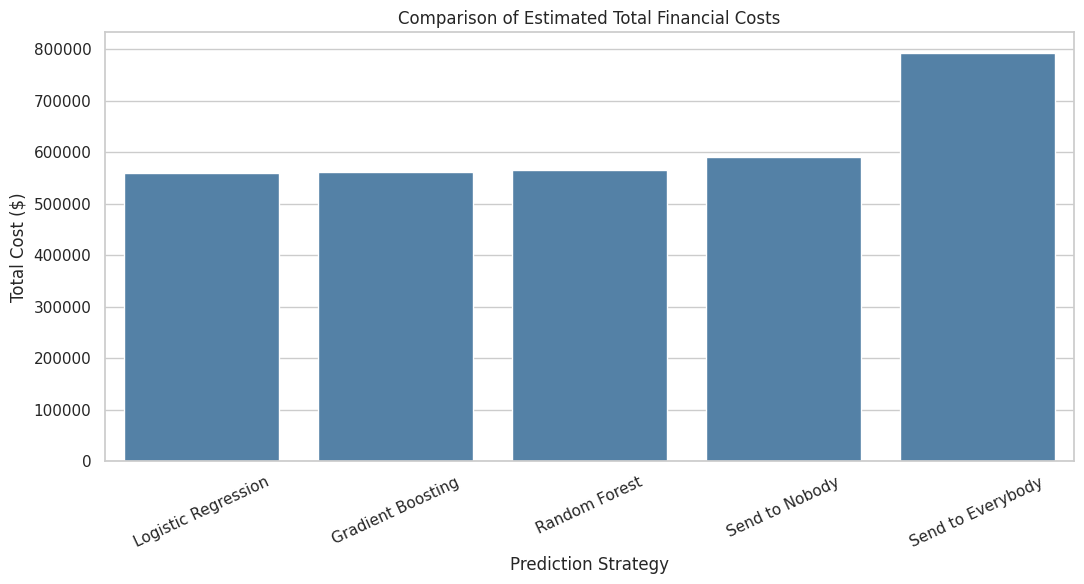


SENSITIVITY ANALYSIS


,mean,min,max
Model,,,
Logistic Regression,616463.00,371408.00,955019.0
Gradient Boosting,617041.22,372492.25,954739.0
Random Forest,618023.83,375441.50,959635.0



Lowest-cost model under initial assumptions:
Logistic Regression


In [37]:

# ============================================================
#  FINANCIAL COST EVALUATION
# H1N1 Vaccine Prediction Challenge - Dataset B
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Define the costs from the assignment
# ------------------------------------------------------------

VACCINE_COST = 500
COMPENSATION_COST = 500
HOSPITAL_COST = 25000

# Initial assumptions - NOT clinically validated.
# These must be researched and justified before submission.

BASE_HOSPITAL_RISK = 0.01
VACCINE_RISK_REDUCTION = 0.50

print("Financial evaluation initialised.")


# ------------------------------------------------------------
# 2. Estimate individual hospitalisation risk
# ------------------------------------------------------------

def estimate_hospital_risk(
    features,
    base_risk=0.01,
    risk_reduction=0.50
):
    """
    Estimate conditional hospitalisation probabilities.

    All participants are assumed infected, in accordance
    with the challenge rules.

    Risk adjustments are illustrative assumptions.
    They must not be presented as clinical findings.
    """

    # Illustrative age-related relative risk multipliers
    age_multipliers = {
        "18 - 34 Years": 0.6,
        "35 - 44 Years": 0.8,
        "45 - 54 Years": 1.0,
        "55 - 64 Years": 1.5,
        "65+ Years": 2.5
    }

    # Assign a multiplier based on the respondent's age
    age_factor = (
        features["age_group"]
        .map(age_multipliers)
        .fillna(1.0)
        .to_numpy()
    )

    # Use training-only median for missing chronic counts
    chronic_train = pd.to_numeric(
        X_train["number_chronic_med_conditions"],
        errors="coerce"
    )

    chronic_median = chronic_train.median()

    chronic_conditions = (
        pd.to_numeric(
            features["number_chronic_med_conditions"],
            errors="coerce"
        )
        .fillna(chronic_median)
        .clip(lower=0)
        .to_numpy()
    )

    # Illustrative 40% relative risk increase
    # for each additional chronic medical condition
    chronic_factor = 1 + (0.40 * chronic_conditions)

    # Hospitalisation probability without vaccination
    risk_without = np.clip(
        base_risk * age_factor * chronic_factor,
        0,
        1
    )

    # Hospitalisation probability with vaccination
    risk_with = risk_without * (1 - risk_reduction)

    return risk_without, risk_with


# ------------------------------------------------------------
# 3. Make cost-optimal allocation decisions
# ------------------------------------------------------------

def make_cost_decisions(
    probabilities,
    risk_without,
    risk_with
):
    """
    Allocate a vaccine when the estimated financial
    benefit exceeds the additional allocation cost.

    probabilities = predicted vaccine acceptance chances
    """

    probabilities = np.asarray(probabilities)

    # Reduction in hospitalisation risk if vaccinated
    risk_difference = risk_without - risk_with

    # Expected financial benefit of sending a vaccine:
    # avoided compensation plus avoided hospital costs
    expected_benefit = probabilities * (
        COMPENSATION_COST
        + HOSPITAL_COST * risk_difference
    )

    # Compare benefit against the vaccine delivery cost
    allocation = (
        expected_benefit > VACCINE_COST
    ).astype(int)

    return allocation


# ------------------------------------------------------------
# 4. Calculate total validation costs
# ------------------------------------------------------------

def calculate_total_cost(
    actual,
    allocation,
    risk_without,
    risk_with
):
    """
    Calculate vaccination, compensation and
    expected hospitalisation costs.

    We use observed vaccination as a proxy for
    willingness to accept vaccination.
    """

    actual = np.asarray(actual).astype(int)
    allocation = np.asarray(allocation).astype(int)

    # Cost of every vaccine sent, including unused ones
    vaccination_cost = (
        allocation.sum() * VACCINE_COST
    )

    # Compensation for people who wanted a vaccine
    # but were not allocated one
    missed_vaccines = (
        (actual == 1) & (allocation == 0)
    )

    compensation_cost = (
        missed_vaccines.sum() * COMPENSATION_COST
    )

    # A vaccine is received only if allocated
    # AND the respondent accepts it
    vaccinated = (
        (actual == 1) & (allocation == 1)
    )

    # Estimate hospitalisation probability per person
    hospital_probabilities = np.where(
        vaccinated,
        risk_with,
        risk_without
    )

    hospitalisation_cost = (
        hospital_probabilities.sum() * HOSPITAL_COST
    )

    total_cost = (
        vaccination_cost
        + compensation_cost
        + hospitalisation_cost
    )

    return {
        "Vaccine Cost": vaccination_cost,
        "Compensation Cost": compensation_cost,
        "Hospitalisation Cost": hospitalisation_cost,
        "Total Cost": total_cost,
        "Vaccines Sent": int(allocation.sum())
    }


# ------------------------------------------------------------
# 5. Calculate risk for the validation dataset
# ------------------------------------------------------------

risk_without, risk_with = estimate_hospital_risk(
    X_val,
    base_risk=BASE_HOSPITAL_RISK,
    risk_reduction=VACCINE_RISK_REDUCTION
)

print("\nHospitalisation risk assumptions:")
print("Base hospital risk:", BASE_HOSPITAL_RISK)
print("Assumed risk reduction:", VACCINE_RISK_REDUCTION)


# ------------------------------------------------------------
# 6. Compare the three machine learning models
# ------------------------------------------------------------

cost_results = []

for model_name, probabilities in validation_probs.items():

    # Determine which people receive vaccines
    predictions = make_cost_decisions(
        probabilities,
        risk_without,
        risk_with
    )

    # Calculate financial outcomes using known labels
    costs = calculate_total_cost(
        y_val,
        predictions,
        risk_without,
        risk_with
    )

    cost_results.append({
        "Model": model_name,
        **costs
    })

# ------------------------------------------------------------
# 7. Add two allocation baselines
# ------------------------------------------------------------

baseline_allocations = {
    "Send to Nobody": np.zeros(len(y_val), dtype=int),
    "Send to Everybody": np.ones(len(y_val), dtype=int)
}

for name, predictions in baseline_allocations.items():

    costs = calculate_total_cost(
        y_val,
        predictions,
        risk_without,
        risk_with
    )

    cost_results.append({
        "Model": name,
        **costs
    })

# ------------------------------------------------------------
# 8. Display and rank financial results
# ------------------------------------------------------------

cost_results_df = pd.DataFrame(cost_results)

# Lower total cost is better
cost_results_df = cost_results_df.sort_values(
    "Total Cost",
    ascending=True
).reset_index(drop=True)

cost_results_df["Cost per Person"] = (
    cost_results_df["Total Cost"] / len(y_val)
)

print("\nFINANCIAL COST COMPARISON")
display(cost_results_df.round(2))


# ------------------------------------------------------------
# 9. Visualise total costs
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

sns.barplot(
    data=cost_results_df,
    x="Model",
    y="Total Cost",
    color="steelblue"
)

plt.title("Comparison of Estimated Total Financial Costs")
plt.xlabel("Prediction Strategy")
plt.ylabel("Total Cost ($)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Test multiple hospitalisation-risk scenarios
# ------------------------------------------------------------

# These represent sensitivity-analysis assumptions,
# not verified epidemiological probabilities.

base_risks = [0.005, 0.01, 0.02]
risk_reductions = [0.30, 0.50, 0.70]

scenario_results = []

for base_risk in base_risks:

    for reduction in risk_reductions:

        # Recalculate hospitalisation risk
        r0, r1 = estimate_hospital_risk(
            X_val,
            base_risk=base_risk,
            risk_reduction=reduction
        )

        for model_name, probs in validation_probs.items():

            # Adapt decisions to each risk scenario
            allocation = make_cost_decisions(
                probs, r0, r1
            )

            # Evaluate financial impact
            scenario_cost = calculate_total_cost(
                y_val,
                allocation,
                r0,
                r1
            )

            scenario_results.append({
                "Base Risk": base_risk,
                "Risk Reduction": reduction,
                "Model": model_name,
                "Total Cost": scenario_cost["Total Cost"]
            })

scenario_results_df = pd.DataFrame(scenario_results)

# Compare average costs across the nine hypothetical
# scenarios as a robustness diagnostic only
scenario_summary = (
    scenario_results_df
    .groupby("Model")["Total Cost"]
    .agg(["mean", "min", "max"])
    .sort_values("mean")
)

print("\nSENSITIVITY ANALYSIS")
display(scenario_summary.round(2))


# ------------------------------------------------------------
# 11. Identify the preliminary lowest-cost model
# ------------------------------------------------------------

# Exclude the simple allocation baselines
model_only_results = cost_results_df[
    cost_results_df["Model"].isin(validation_probs.keys())
]

best_cost_model_name = (
    model_only_results.iloc[0]["Model"]
)

best_cost_pipeline = trained_models[
    best_cost_model_name
]

print("\nLowest-cost model under initial assumptions:")
print(best_cost_model_name)

# print("Financial results are ready for critical analysis.")


In [23]:

# ============================================================
# FIX
# ============================================================

import pandas as pd
import numpy as np

# 1. Check actual age categories in the training data
print("ACTUAL AGE CATEGORIES:")
print(X_train["age_group"].value_counts(dropna=False))

# 2. Check categories expected by the risk model
expected_age_categories = {
    "18 - 34 Years",
    "35 - 44 Years",
    "45 - 54 Years",
    "55 - 64 Years",
    "65+ Years"
}

# 3. Identify categories not recognised by the model
actual_categories = set(
    X_train["age_group"].dropna().unique()
)

unmatched = actual_categories - expected_age_categories

print("\nUNMATCHED AGE CATEGORIES:")
print(unmatched)

# 4. Calculate percentage of age values recognised
matched = X_train["age_group"].isin(
    expected_age_categories
)

match_percentage = matched.mean() * 100

print(
    f"\nAge category match rate: "
    f"{match_percentage:.2f}%"
)

# 5. Check the estimated hospitalisation probabilities
risk_without, risk_with = estimate_hospital_risk(
    X_val,
    base_risk=BASE_HOSPITAL_RISK,
    risk_reduction=VACCINE_RISK_REDUCTION
)

risk_summary = pd.DataFrame({
    "Without Vaccine": risk_without,
    "With Vaccine": risk_with
})

print("\nHOSPITALISATION RISK SUMMARY:")
display(risk_summary.describe().round(4))




ACTUAL AGE CATEGORIES:
age_group
65+ Years        951
55 - 64 Years    874
45 - 54 Years    727
18 - 34 Years    721
35 - 44 Years    531
Name: count, dtype: int64

UNMATCHED AGE CATEGORIES:
set()

Age category match rate: 100.00%

HOSPITALISATION RISK SUMMARY:


,Without Vaccine,With Vaccine
count,952.0000,952.0000
mean,0.0169,0.0085
std,0.0106,0.0053
min,0.0060,0.0030
25%,0.0080,0.0040
50%,0.0142,0.0071
75%,0.0250,0.0125
max,0.0650,0.0325



FIX 1 Done



## Critical Analysis of Financial Evaluation

### Cost-Based Evaluation

Our financial evaluation considers vaccine distribution,
compensation payments and expected hospitalisation costs.

Unlike conventional classification accuracy, this
evaluation accounts for the financial consequences
of individual vaccination allocation decisions.

### Individualised Decision Thresholds

Instead of using a fixed probability threshold of 0.5,
we calculate whether the expected financial benefit
of allocating a vaccine exceeds its cost.

Respondents with greater estimated hospitalisation
risk may have a lower allocation threshold.

### Model Comparison

Logistic Regression, Random Forest and Gradient Boosting
were evaluated on the same holdout validation data.

Total estimated financial cost was used as the
primary comparison measure.

We also compared the models against strategies of
allocating vaccines to everybody and to nobody.

### Sensitivity Analysis

We investigated different baseline hospitalisation
probabilities and vaccination-related risk reductions.

This helps assess whether model rankings remain stable
when key assumptions change.

### Important Limitations

Hospitalisation outcomes are unavailable in the
supplied dataset.

Consequently, we must estimate hospitalisation risk
using external evidence and explicit assumptions.

The current risk multipliers are illustrative and
must be researched and justified.

The target variable records historical vaccination,
which is treated as a proxy for willingness to accept
vaccination. These concepts may not be identical.

Additionally, model selection on one validation set
may produce optimistic results. Cross-validation
and further robustness checks are necessary.

### Conclusion

The financial evaluation provides a more suitable
basis for the challenge than classification accuracy
alone.

The next stage will investigate hyperparameter tuning
and model improvements, followed by final model ranking
and submission.


Hyperparameter Tuning and Model Optimisation


#  Hyperparameter Tuning and Model Optimisation

## Objective

The objective of this stage is to improve model
performance through systematic hyperparameter tuning.

Three algorithms are optimised:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting

## Hyperparameter Optimisation

RandomizedSearchCV is used to explore multiple
hyperparameter combinations.

The search investigates:

### Logistic Regression
- Regularisation strength (C)
- Class weighting

### Random Forest
- Number of decision trees
- Maximum tree depth
- Minimum samples per leaf

### Gradient Boosting
- Number of boosting iterations
- Learning rate
- Maximum tree depth

##  Cross-Validation Strategy

Five-fold stratified cross-validation is used
within the training subset.

All preprocessing operations are included in
the machine learning pipelines to prevent
data leakage between folds.

##  Optimisation Metric

The primary optimisation metric is the negative
estimated financial cost per respondent.

The cost includes:

- Vaccine distribution costs
- Compensation costs
- Expected hospitalisation costs

The score is negative because scikit-learn
maximises scoring functions, whereas our
objective is to minimise financial cost.

Hospitalisation assumptions are provisional
and must be supported by research.

##  Model Selection

The tuned models are compared using:

1. Mean cross-validation financial cost
2. Standard deviation across validation folds
3. Holdout validation financial cost
4. ROC-AUC
5. Brier score

The lowest-cost model is identified using
cross-validation results, while the holdout
set provides an additional performance check.



TUNING: Logistic Regression

Best Hyperparameters:
{'classifier__class_weight': None, 'classifier__C': 0.05}
CV Cost per Respondent ($): 576.09
Cross-validation Cost SD ($): 7.56

Holdout Total Cost ($): 561735.0
Validation ROC-AUC: 0.8362

TUNING: Random Forest

Best Hyperparameters:
{'classifier__n_estimators': 220, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': None}
CV Cost per Respondent ($): 577.78
Cross-validation Cost SD ($): 7.94

Holdout Total Cost ($): 566425.0
Validation ROC-AUC: 0.8297

TUNING: Gradient Boosting

Best Hyperparameters:
{'classifier__n_estimators': 150, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1}
CV Cost per Respondent ($): 575.45
Cross-validation Cost SD ($): 6.73

Holdout Total Cost ($): 560117.5
Validation ROC-AUC: 0.8413

OPTIMISED MODEL COMPARISON


,Model,CV Cost/Person ($),CV Cost SD ($),Validation Cost ($),Vaccines Sent,Accuracy,ROC-AUC,Brier Score
0,Gradient Boosting,575.4488,6.7334,560117.5,171,0.7763,0.8413,0.1552
1,Logistic Regression,576.0855,7.5641,561735.0,164,0.7784,0.8362,0.1570
2,Random Forest,577.7803,7.9377,566425.0,116,0.7710,0.8297,0.1636



SELECTED HYPERPARAMETERS


,Model,Best Parameters
0,Gradient Boosting,"{'classifier__n_estimators': 150, 'classifier_..."
1,Logistic Regression,"{'classifier__class_weight': None, 'classifier..."
2,Random Forest,"{'classifier__n_estimators': 220, 'classifier_..."


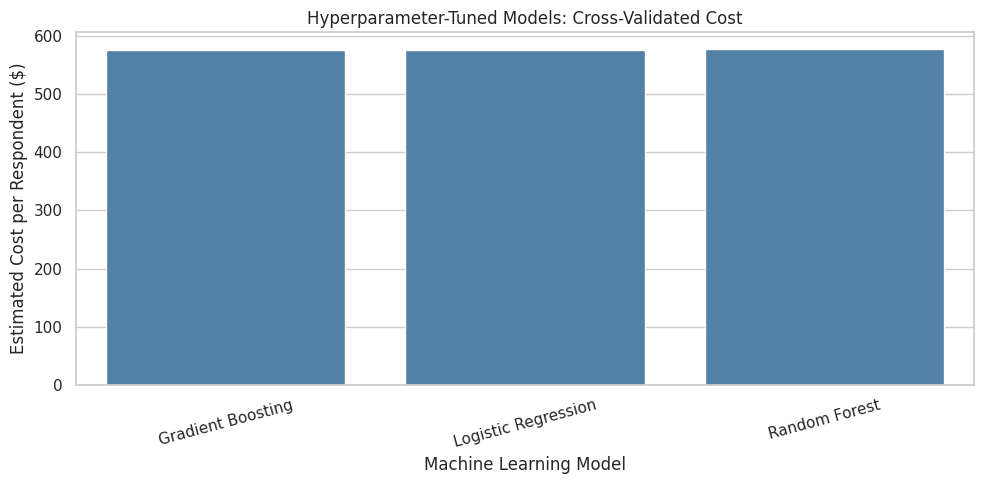


BEST TUNED MODEL:
Gradient Boosting


In [38]:

# ============================================================
#  HYPERPARAMETER TUNING AND OPTIMISATION
# Dataset B - H1N1 Vaccine Challenge
# ============================================================

# ------------------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 2. Define the financial cost scoring function
# ------------------------------------------------------------

def financial_cost_scorer(estimator, X_fold, y_fold):
    """
    Calculate negative financial cost per respondent.

    Uses the cost functions and provisional
    hospitalisation assumptions from Step 8.

    Higher returned score = lower estimated cost.
    """

    # Predict probability of vaccine acceptance
    probabilities = estimator.predict_proba(
        X_fold
    )[:, 1]

    # Estimate hospitalisation risks
    risk_without, risk_with = estimate_hospital_risk(
        X_fold,
        base_risk=BASE_HOSPITAL_RISK,
        risk_reduction=VACCINE_RISK_REDUCTION
    )

    # Determine cost-based vaccine allocations
    decisions = make_cost_decisions(
        probabilities,
        risk_without,
        risk_with
    )

    # Calculate estimated financial costs
    costs = calculate_total_cost(
        y_fold,
        decisions,
        risk_without,
        risk_with
    )

    # Return negative cost per person
    # so RandomizedSearchCV can maximise the score
    return -costs["Total Cost"] / len(y_fold)


# ------------------------------------------------------------
# 3. Configure cross-validation
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. Define algorithms and hyperparameter search spaces
# ------------------------------------------------------------

search_spaces = {

    "Logistic Regression": {

        "model": LogisticRegression(
            max_iter=2500,
            random_state=42
        ),

        "params": {
            "classifier__C": [0.05, 0.2, 1.0, 5.0],
            "classifier__class_weight": [
                None, "balanced"
            ]
        }
    },

    "Random Forest": {

        "model": RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ),

        "params": {
            "classifier__n_estimators": [120, 220],
            "classifier__max_depth": [8, None],
            "classifier__min_samples_leaf": [2, 5]
        }
    },

    "Gradient Boosting": {

        "model": GradientBoostingClassifier(
            random_state=42
        ),

        "params": {
            "classifier__n_estimators": [90, 150],
            "classifier__learning_rate": [0.05, 0.1],
            "classifier__max_depth": [2, 3]
        }
    }
}

# ------------------------------------------------------------
# 5. Run hyperparameter optimisation
# ------------------------------------------------------------

tuned_models = {}
tuned_validation_probs = {}
tuned_validation_allocations = {}

tuning_results = []

for model_name, configuration in search_spaces.items():

    print("\n" + "=" * 55)
    print("TUNING:", model_name)
    print("=" * 55)

    # Put preprocessing inside the pipeline.
    # This ensures fold-specific preprocessing.
    pipeline = Pipeline(steps=[

        (
            "preprocessing",
            clone(preprocessor)
        ),

        (
            "classifier",
            clone(configuration["model"])
        )

    ])

    # Test four randomly selected combinations
    # using five-fold stratified cross-validation
    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=configuration["params"],

        n_iter=4,

        scoring=financial_cost_scorer,

        cv=cv,

        random_state=42,

        n_jobs=2,

        refit=True,

        error_score="raise"
    )

    # Tune using the training subset only
    search.fit(X_train, y_train)

    # Best fitted pipeline after cross-validation
    best_pipeline = search.best_estimator_

    # Display selected hyperparameters
    print("\nBest Hyperparameters:")
    print(search.best_params_)

    # Convert negative score into positive cost
    cv_cost = -search.best_score_

    # Variation across the five validation folds
    cv_std = search.cv_results_[
        "std_test_score"
    ][search.best_index_]

    print(
        "CV Cost per Respondent ($):",
        round(cv_cost, 2)
    )

    print(
        "Cross-validation Cost SD ($):",
        round(cv_std, 2)
    )

    # --------------------------------------------------------
    # 6. Evaluate on the untouched holdout set
    # --------------------------------------------------------

    # Predict vaccination acceptance probabilities
    probabilities = best_pipeline.predict_proba(
        X_val
    )[:, 1]

    # Standard 0.5 predictions for classification accuracy
    class_predictions = (
        probabilities >= 0.5
    ).astype(int)

    # Estimate hospitalisation risk for validation data
    risk_without, risk_with = estimate_hospital_risk(
        X_val,
        base_risk=BASE_HOSPITAL_RISK,
        risk_reduction=VACCINE_RISK_REDUCTION
    )

    # Calculate cost-based allocation decisions
    allocation = make_cost_decisions(
        probabilities,
        risk_without,
        risk_with
    )

    # Calculate holdout financial costs
    costs = calculate_total_cost(
        y_val,
        allocation,
        risk_without,
        risk_with
    )

    # Evaluate classification and probability quality
    auc = roc_auc_score(
        y_val,
        probabilities
    )

    accuracy = accuracy_score(
        y_val,
        class_predictions
    )

    brier = brier_score_loss(
        y_val,
        probabilities
    )

    # Save the fitted model and predictions
    tuned_models[model_name] = best_pipeline

    tuned_validation_probs[model_name] = probabilities

    tuned_validation_allocations[model_name] = allocation

    # Record model performance
    tuning_results.append({

        "Model": model_name,

        "CV Cost/Person ($)": cv_cost,

        "CV Cost SD ($)": cv_std,

        "Validation Cost ($)": costs["Total Cost"],

        "Vaccines Sent": costs["Vaccines Sent"],

        "Accuracy": accuracy,

        "ROC-AUC": auc,

        "Brier Score": brier,

        "Best Parameters": str(search.best_params_)
    })

    print(
        "\nHoldout Total Cost ($):",
        round(costs["Total Cost"], 2)
    )

    print("Validation ROC-AUC:", round(auc, 4))

# ------------------------------------------------------------
# 7. Compare optimised model performance
# ------------------------------------------------------------

tuning_results_df = pd.DataFrame(tuning_results)

# Rank models by cross-validated financial cost
# Lower estimated cost is better
tuning_results_df = tuning_results_df.sort_values(
    "CV Cost/Person ($)",
    ascending=True
).reset_index(drop=True)

print("\nOPTIMISED MODEL COMPARISON")

display(
    tuning_results_df.drop(
        columns=["Best Parameters"]
    ).round(4)
)

# Show the hyperparameters selected for each model
print("\nSELECTED HYPERPARAMETERS")

display(
    tuning_results_df[
        ["Model", "Best Parameters"]
    ]
)

# ------------------------------------------------------------
# 8. Plot tuned model costs
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_results_df,
    x="Model",
    y="CV Cost/Person ($)",
    color="steelblue"
)

plt.title(
    "Hyperparameter-Tuned Models: Cross-Validated Cost"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Estimated Cost per Respondent ($)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 9. Identify the leading tuned model
# ------------------------------------------------------------

# Select using cross-validation, not holdout performance
best_tuned_model_name = (
    tuning_results_df.iloc[0]["Model"]
)

best_tuned_pipeline = tuned_models[
    best_tuned_model_name
]

print("\nBEST TUNED MODEL:")
print(best_tuned_model_name)

# print("\nStep 9 completed successfully!")
# print("All tuned models have been saved in memory.")


Logistic Regression: LogisticRegression
Random Forest: RandomForestClassifier
Logistic Regression features: 103
Random Forest features: 103

Calculating Logistic Regression SHAP...

Calculating Random Forest SHAP...

LOGISTIC REGRESSION TOP 10:


,Feature,Mean Absolute SHAP,Rank
0,binary__missingindicator_health_insurance,0.6221,1
1,binary__doctor_recc_h1n1,0.4537,2
2,categorical__opinion_h1n1_vacc_effective_5,0.3790,3
3,categorical__opinion_h1n1_risk_1,0.3524,4
4,categorical__opinion_h1n1_risk_4,0.1906,5
5,numerical__h1n1_knowledge,0.1652,6
6,categorical__opinion_h1n1_risk_2,0.1473,7
7,binary__health_worker,0.1288,8
8,numerical__h1n1_concern,0.1287,9
9,categorical__opinion_h1n1_sick_from_vacc_2,0.1144,10



RANDOM FOREST TOP 10:


,Feature,Mean Absolute SHAP,Rank
0,binary__doctor_recc_h1n1,0.0847,1
1,binary__missingindicator_health_insurance,0.0692,2
2,categorical__opinion_h1n1_vacc_effective_5,0.0561,3
3,categorical__opinion_h1n1_risk_4,0.0409,4
4,categorical__opinion_h1n1_risk_1,0.0404,5
5,numerical__h1n1_knowledge,0.0179,6
6,binary__health_worker,0.0178,7
7,categorical__opinion_h1n1_risk_5,0.0161,8
8,numerical__h1n1_concern,0.0149,9
9,categorical__opinion_h1n1_risk_2,0.0138,10


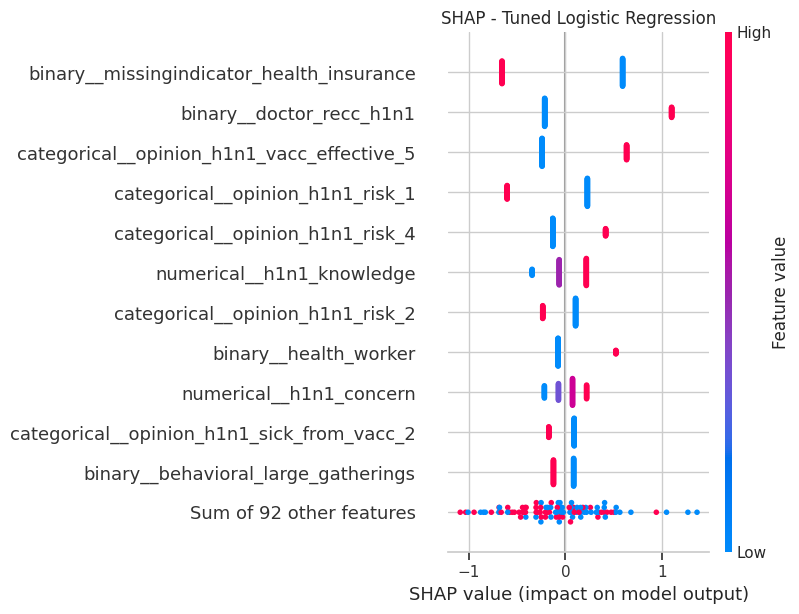

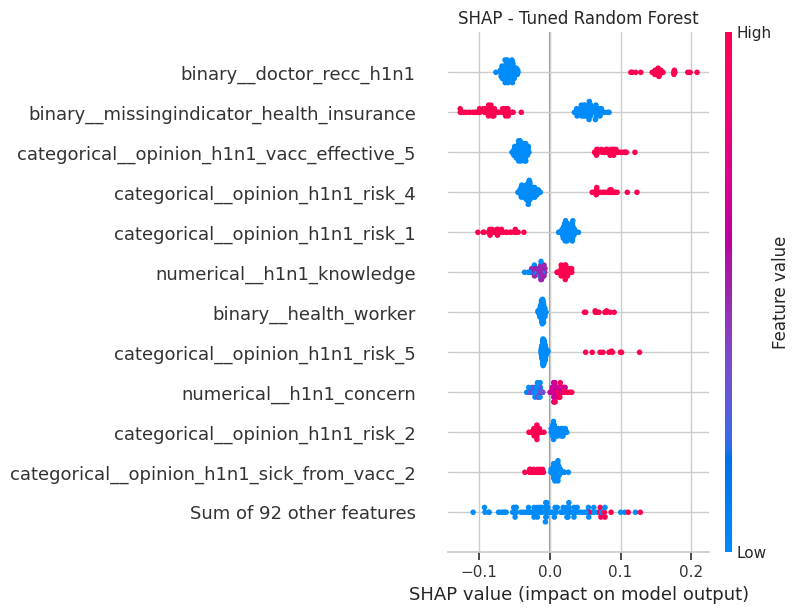


SHAP FEATURE RANKING COMPARISON:


,Feature,Logistic Regression Rank,Random Forest Rank,Mean Rank
8,binary__doctor_recc_h1n1,2,1,1.5
20,binary__missingindicator_health_insurance,1,2,1.5
83,categorical__opinion_h1n1_vacc_effective_5,3,3,3.0
67,categorical__opinion_h1n1_risk_1,4,5,4.5
70,categorical__opinion_h1n1_risk_4,5,4,4.5
95,numerical__h1n1_knowledge,6,6,6.0
10,binary__health_worker,8,7,7.5
68,categorical__opinion_h1n1_risk_2,7,10,8.5
94,numerical__h1n1_concern,9,9,9.0
74,categorical__opinion_h1n1_sick_from_vacc_2,10,11,10.5



FIX 4 COMPLETED SUCCESSFULLY!


In [32]:

# ============================================================

# Logistic Regression and Random Forest
# H1N1 Vaccine Prediction Challenge
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. Retrieve existing tuned models
# ------------------------------------------------------------

lr_pipeline = tuned_models["Logistic Regression"]
rf_pipeline = tuned_models["Random Forest"]

# Retrieve fitted preprocessing pipelines
lr_preprocessor = lr_pipeline.named_steps["preprocessing"]
rf_preprocessor = rf_pipeline.named_steps["preprocessing"]

# Retrieve fitted classifiers
lr_classifier = lr_pipeline.named_steps["classifier"]
rf_classifier = rf_pipeline.named_steps["classifier"]

print("Logistic Regression:", type(lr_classifier).__name__)
print("Random Forest:", type(rf_classifier).__name__)

# ------------------------------------------------------------
# 2. Select a reproducible sample
# ------------------------------------------------------------

# Background data must come from training data
X_background = X_train.sample(
    n=min(80, len(X_train)),
    random_state=42
)

# Explain predictions on unseen validation observations
X_explain = X_val.sample(
    n=min(100, len(X_val)),
    random_state=42
)

# ------------------------------------------------------------
# 3. Helper function for transformed data
# ------------------------------------------------------------

def prepare_shap_data(preprocessor, data):

    transformed = preprocessor.transform(data)

    # Convert sparse output to dense when required
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()

    return np.asarray(transformed)

# Apply each model's own fitted preprocessor
lr_background = prepare_shap_data(
    lr_preprocessor, X_background
)

lr_validation = prepare_shap_data(
    lr_preprocessor, X_explain
)

rf_validation = prepare_shap_data(
    rf_preprocessor, X_explain
)

# Get encoded feature names
lr_features = lr_preprocessor.get_feature_names_out()
rf_features = rf_preprocessor.get_feature_names_out()

print("Logistic Regression features:", len(lr_features))
print("Random Forest features:", len(rf_features))

# ------------------------------------------------------------
# 4. Logistic Regression SHAP
# ------------------------------------------------------------

print("\nCalculating Logistic Regression SHAP...")

lr_explainer = shap.LinearExplainer(
    lr_classifier,
    lr_background
)

lr_shap = lr_explainer(lr_validation)

lr_shap.feature_names = list(lr_features)

# ------------------------------------------------------------
# 5. Random Forest SHAP
# ------------------------------------------------------------

print("\nCalculating Random Forest SHAP...")

rf_explainer = shap.TreeExplainer(
    rf_classifier
)

rf_shap = rf_explainer(rf_validation)

# Some SHAP versions return values for both classes.
# Select class 1: vaccinated.
if rf_shap.values.ndim == 3:
    rf_shap = rf_shap[..., 1]

rf_shap.feature_names = list(rf_features)

# ------------------------------------------------------------
# 6. Calculate feature importance
# ------------------------------------------------------------

def calculate_shap_importance(shap_result, feature_names):

    # Average absolute contribution across observations
    importance = np.abs(
        shap_result.values
    ).mean(axis=0)

    result = pd.DataFrame({
        "Feature": feature_names,
        "Mean Absolute SHAP": importance
    })

    result = result.sort_values(
        "Mean Absolute SHAP",
        ascending=False
    ).reset_index(drop=True)

    # Rank 1 means most influential feature
    result["Rank"] = np.arange(1, len(result) + 1)

    return result


lr_importance = calculate_shap_importance(
    lr_shap, lr_features
)

rf_importance = calculate_shap_importance(
    rf_shap, rf_features
)

print("\nLOGISTIC REGRESSION TOP 10:")
display(lr_importance.head(10).round(4))

print("\nRANDOM FOREST TOP 10:")
display(rf_importance.head(10).round(4))

# ------------------------------------------------------------
# 7. Plot Logistic Regression SHAP
# ------------------------------------------------------------

shap.plots.beeswarm(
    lr_shap,
    max_display=12,
    show=False
)

plt.title("SHAP - Tuned Logistic Regression")
plt.tight_layout()

plt.savefig(
    "shap_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Plot Random Forest SHAP
# ------------------------------------------------------------

shap.plots.beeswarm(
    rf_shap,
    max_display=12,
    show=False
)

plt.title("SHAP - Tuned Random Forest")
plt.tight_layout()

plt.savefig(
    "shap_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Compare feature rankings
# ------------------------------------------------------------

comparison = lr_importance[
    ["Feature", "Rank"]
].rename(
    columns={"Rank": "Logistic Regression Rank"}
)

comparison = comparison.merge(
    rf_importance[
        ["Feature", "Rank"]
    ].rename(
        columns={"Rank": "Random Forest Rank"}
    ),
    on="Feature",
    how="outer"
)

# Smaller mean rank = consistently greater importance
comparison["Mean Rank"] = comparison[
    ["Logistic Regression Rank", "Random Forest Rank"]
].mean(axis=1)

comparison = comparison.sort_values(
    "Mean Rank"
)

print("\nSHAP FEATURE RANKING COMPARISON:")
display(comparison.head(15).round(2))

# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

lr_importance.to_csv(
    "shap_logistic_importance.csv",
    index=False
)

rf_importance.to_csv(
    "shap_random_forest_importance.csv",
    index=False
)

comparison.to_csv(
    "shap_model_comparison.csv",
    index=False
)

# print("\nFIX ")



# Explainable AI (XAI): Permutation Feature Importance

## Objective

The aim of this analysis is to understand which
features contribute most strongly to predicting
H1N1 vaccination outcomes.

## Methodology

Permutation Feature Importance measures how much
model performance changes when an individual
feature is randomly shuffled.

A large reduction in performance suggests that
the model relies strongly on that feature.

We apply the technique to:

1. Tuned Logistic Regression
2. Tuned Random Forest
3. Tuned Gradient Boosting

## Evaluation

ROC-AUC is used to measure the change in predictive
performance.

The analysis uses the holdout validation dataset,
which was not used to fit the models.

We repeat the permutation three times per feature
to investigate the variation in importance scores.

## Limitations

Permutation importance measures predictive reliance,
not causal influence.

Correlated features may share predictive information,
causing their individual importance to be understated.

The results also depend on the selected validation
dataset and evaluation metric.

Importantly, importance measured using ROC-AUC may
differ from importance measured using the challenge's
financial-cost metric.



Analysing: Logistic Regression

Top 10 Important Features:


,Feature,Importance,Std,Model
12,health_insurance,0.0695,0.0117,Logistic Regression
9,doctor_recc_h1n1,0.0672,0.0090,Logistic Regression
14,opinion_h1n1_risk,0.0319,0.0009,Logistic Regression
13,opinion_h1n1_vacc_effective,0.0303,0.0055,Logistic Regression
11,health_worker,0.0095,0.0011,Logistic Regression
27,employment_sector,0.0047,0.0003,Logistic Regression
18,race,0.0034,0.0009,Logistic Regression
17,education,0.0026,0.0013,Logistic Regression
28,number_chronic_med_conditions,0.0022,0.0002,Logistic Regression
6,behavioral_large_gatherings,0.0022,0.0014,Logistic Regression


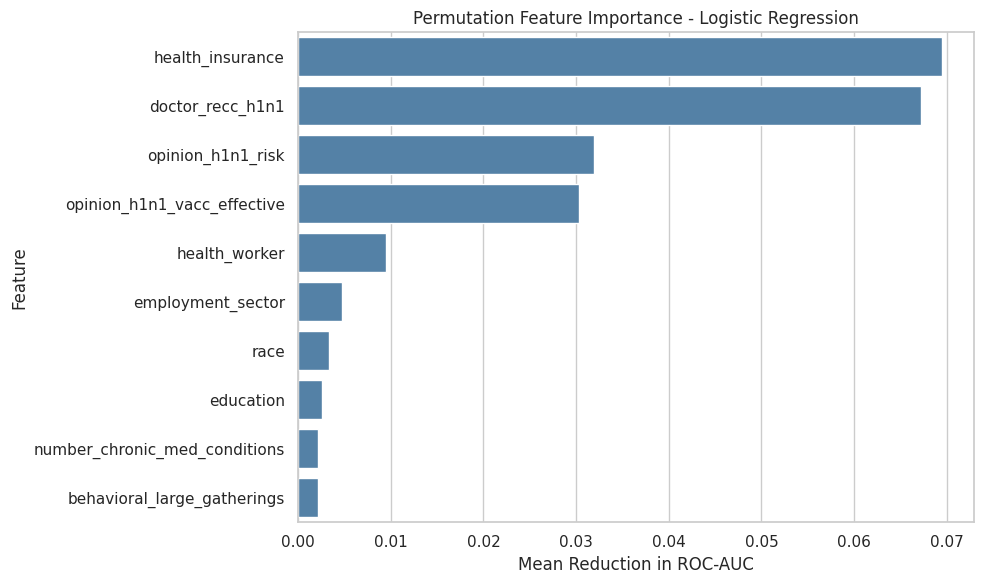


Analysing: Random Forest

Top 10 Important Features:


,Feature,Importance,Std,Model
9,doctor_recc_h1n1,0.0783,0.0077,Random Forest
12,health_insurance,0.0555,0.0108,Random Forest
14,opinion_h1n1_risk,0.0332,0.0055,Random Forest
13,opinion_h1n1_vacc_effective,0.0289,0.0085,Random Forest
11,health_worker,0.0074,0.0012,Random Forest
17,education,0.0031,0.0017,Random Forest
1,h1n1_knowledge,0.0029,0.0002,Random Forest
19,sex,0.0019,0.0003,Random Forest
27,employment_sector,0.0015,0.0012,Random Forest
21,marital_status,0.0015,0.0005,Random Forest


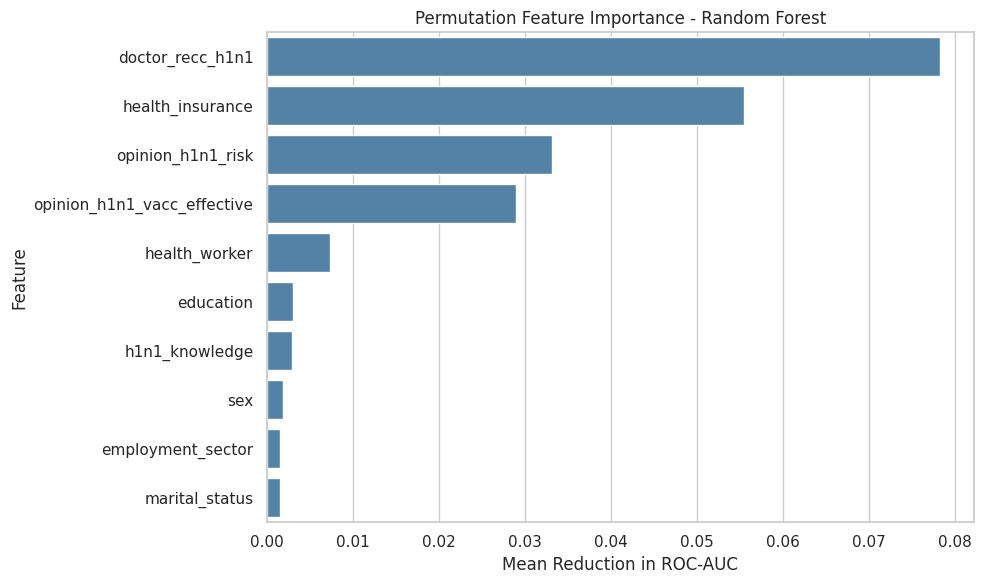


Analysing: Gradient Boosting

Top 10 Important Features:


,Feature,Importance,Std,Model
9,doctor_recc_h1n1,0.0738,0.0077,Gradient Boosting
12,health_insurance,0.0678,0.0142,Gradient Boosting
14,opinion_h1n1_risk,0.0364,0.0038,Gradient Boosting
13,opinion_h1n1_vacc_effective,0.0320,0.0066,Gradient Boosting
11,health_worker,0.0130,0.0018,Gradient Boosting
18,race,0.0040,0.0010,Gradient Boosting
27,employment_sector,0.0025,0.0010,Gradient Boosting
17,education,0.0022,0.0010,Gradient Boosting
16,age_group,0.0016,0.0001,Gradient Boosting
25,household_adults,0.0016,0.0006,Gradient Boosting


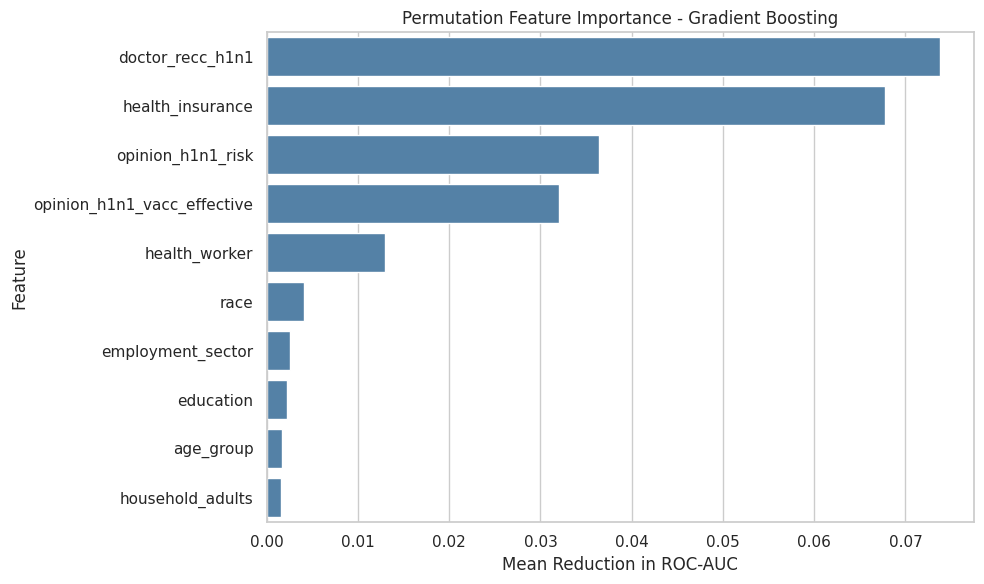


FEATURE IMPORTANCE COMPARISON:


Model,Gradient Boosting,Logistic Regression,Random Forest,Mean Importance
Feature,,,,
doctor_recc_h1n1,0.0738,0.0672,0.0783,0.0731
health_insurance,0.0678,0.0695,0.0555,0.0642
opinion_h1n1_risk,0.0364,0.0319,0.0332,0.0338
opinion_h1n1_vacc_effective,0.0320,0.0303,0.0289,0.0304
health_worker,0.0130,0.0095,0.0074,0.0100
employment_sector,0.0025,0.0047,0.0015,0.0029
race,0.0040,0.0034,0.0013,0.0029
education,0.0022,0.0026,0.0031,0.0026
h1n1_knowledge,0.0015,0.0000,0.0029,0.0015



FIX 2 COMPLETED SUCCESSFULLY!


In [24]:

# ============================================================
# FIX
# H1N1 Vaccine Prediction Challenge
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance

# ------------------------------------------------------------
# 1. Select the tuned machine learning models
# ------------------------------------------------------------

# These pipelines were trained in Step 9

models_to_explain = {
    "Logistic Regression": tuned_models[
        "Logistic Regression"
    ],
    "Random Forest": tuned_models[
        "Random Forest"
    ],
    "Gradient Boosting": tuned_models[
        "Gradient Boosting"
    ]
}

# ------------------------------------------------------------
# 2. Calculate permutation feature importance
# ------------------------------------------------------------

importance_results = []

for model_name, model in models_to_explain.items():

    print("\nAnalysing:", model_name)

    # Permute original input features.
    # The fitted pipeline handles preprocessing.
    result = permutation_importance(
        estimator=model,
        X=X_val,
        y=y_val,
        scoring="roc_auc",
        n_repeats=3,
        random_state=42,
        n_jobs=1
    )

    # Create a table of feature importance values
    importance_df = pd.DataFrame({
        "Feature": X_val.columns,
        "Importance": result.importances_mean,
        "Std": result.importances_std
    })

    # Sort from highest to lowest importance
    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    # Store results for comparing the models
    importance_df["Model"] = model_name

    importance_results.append(importance_df)

    # --------------------------------------------------------
    # 3. Display the ten most important features
    # --------------------------------------------------------

    print("\nTop 10 Important Features:")
    display(importance_df.head(10).round(4))

    # --------------------------------------------------------
    # 4. Visualise feature importance
    # --------------------------------------------------------

    top_features = importance_df.head(10)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=top_features,
        x="Importance",
        y="Feature",
        color="steelblue"
    )

    plt.title(
        f"Permutation Feature Importance - {model_name}"
    )

    plt.xlabel("Mean Reduction in ROC-AUC")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. Combine results from all three models
# ------------------------------------------------------------

all_importance = pd.concat(
    importance_results,
    ignore_index=True
)

# Save results for the report and GitHub
all_importance.to_csv(
    "xai_permutation_importance.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Compare feature rankings across models
# ------------------------------------------------------------

comparison = all_importance.pivot(
    index="Feature",
    columns="Model",
    values="Importance"
)

# Rank features by their average importance
comparison["Mean Importance"] = (
    comparison.mean(axis=1)
)

comparison = comparison.sort_values(
    "Mean Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE COMPARISON:")
display(comparison.head(10).round(4))

# print("\nFIX 2 COMPLETED SUCCESSFULLY!")



## Critical Evaluation of Explainable AI Results

Permutation Feature Importance was applied to
three optimised machine learning algorithms.

The analysis measures each model's reliance on
individual features by observing the reduction
in ROC-AUC after random permutation.

### Model Comparison

The most influential features differed between
the three models, reflecting differences in
their learning mechanisms and complexity.

The findings should be interpreted alongside
the feature importance scores and their variation.

### Model Interpretability

Logistic Regression provides a relatively simple
predictive structure.

Random Forest and Gradient Boosting can capture
nonlinear relationships and interactions, which
may lead to different feature importance rankings.

### Limitations

Permutation importance does not establish
causality or explain the direction of influence.

Correlated variables can also produce misleading
individual importance estimates.

Further analysis using SHAP may help explain
how particular features contribute to individual
model predictions.



##  Hyperparameter Tuning and Critical Analysis

### Optimisation Strategy

We evaluated three supervised machine learning algorithms:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting

RandomizedSearchCV was used to evaluate four
hyperparameter configurations for each algorithm.

Five-fold stratified cross-validation was applied
to the development data.

The primary optimisation objective was to minimise
estimated financial cost per respondent rather than
maximise classification accuracy.

Preprocessing was included within each pipeline
to avoid information leakage across validation folds.

### Cross-Validation Results

| Model | CV Cost per Person | Standard Deviation |
|---|---:|---:|
| Tuned Gradient Boosting | $575.45 | $6.73 |
| Tuned Logistic Regression | $576.09 | $7.56 |
| Tuned Random Forest | $577.78 | $7.94 |

Tuned Gradient Boosting achieved the lowest mean
cross-validation cost of $575.45 per respondent.

It also demonstrated the lowest standard deviation,
suggesting slightly greater stability across folds.

However, the difference between Gradient Boosting
and Logistic Regression was only approximately $0.64
per respondent.

This difference is small relative to cross-validation
variation, so the results do not provide strong
evidence that Gradient Boosting consistently
outperforms Logistic Regression.

### Baseline vs Tuned Model Performance

We compared the original and tuned configurations
using the same holdout validation dataset.

| Model | Baseline Cost | Tuned Cost | Cost Change |
|---|---:|---:|---:|
| Logistic Regression | $560,432.50 | $561,735.00 | +$1,302.50 |
| Random Forest | $564,922.50 | $566,425.00 | +$1,502.50 |
| Gradient Boosting | $561,015.00 | $560,117.50 | -$897.50 |

The results demonstrate that hyperparameter
optimisation did not improve every model.

Gradient Boosting achieved an estimated cost
reduction of $897.50 after tuning.

In contrast, tuned Logistic Regression increased
estimated costs by $1,302.50.

Tuned Random Forest also performed worse, with
estimated costs increasing by $1,502.50.

These findings suggest that the effect of
hyperparameter tuning depends on the model.

Optimisation against development-fold performance
does not guarantee improved performance on
independent validation observations.

###  Classification Performance

| Tuned Model | Accuracy | ROC-AUC | Brier Score |
|---|---:|---:|---:|
| Gradient Boosting | 0.7763 | 0.8413 | 0.1552 |
| Logistic Regression | 0.7784 | 0.8362 | 0.1570 |
| Random Forest | 0.7710 | 0.8297 | 0.1636 |

Tuned Logistic Regression achieved the highest
classification accuracy of 77.84%.

However, tuned Gradient Boosting achieved the
highest ROC-AUC of 0.8413 and the lowest Brier
score of 0.1552.

This indicates that the best algorithm depends
on the evaluation objective.

The Gradient Boosting model demonstrated better
discrimination and probability prediction quality,
whereas Logistic Regression achieved slightly
higher accuracy at the conventional threshold.

### Financial Evaluation

The financial evaluation considered:

- Vaccine distribution costs
- Compensation for missed vaccine allocation
- Expected hospitalisation costs

Gradient Boosting achieved the lowest estimated
holdout cost among the tuned models.

This suggests that financial decision-making
should consider prediction probabilities and
the costs of different allocation decisions,
rather than accuracy alone.

### Limitations

Several limitations must be acknowledged.

First, the hospitalisation-risk estimates and
vaccination effects were based on provisional
assumptions, not observed hospitalisation outcomes.

Second, the target variable records historical
vaccination status, which is being used as a
proxy for willingness to accept an allocated vaccine.

Third, only four hyperparameter configurations
per model were explored.

Fourth, the cross-validation differences between
leading models were small, so ranking uncertainty
remains substantial.

Finally, validation results may not generalise
perfectly to the hidden challenge test dataset.

The model results should therefore be interpreted
as conditional on the assumptions and data used.

### Conclusion

Gradient Boosting was the strongest tuned model
under our provisional financial evaluation assumptions.

Nevertheless, the results show that hyperparameter
tuning does not always improve performance.

Our comparison demonstrates the importance of
evaluating multiple algorithms, assessing
cross-validation variability, and selecting models
using a metric aligned with the practical problem.



## Hyperparameter Tuning and Critical Analysis

### Optimisation Strategy

RandomizedSearchCV was used to optimise Logistic
Regression, Random Forest and Gradient Boosting.

Four hyperparameter configurations were evaluated
per model using five-fold stratified cross-validation.

The objective was to minimise estimated financial
cost per respondent rather than maximise accuracy.

### Cross-Validation Results

The model with the lowest estimated cross-validation
financial cost was [INSERT MODEL NAME].

Its mean estimated cost per respondent was
$[INSERT VALUE], with a cross-validation
standard deviation of $[INSERT VALUE].

### Model Improvements

The tuned models were compared with their baseline
configurations from previous experiments.

[DESCRIBE WHETHER COSTS IMPROVED AND BY HOW MUCH.]

Changes in hyperparameters may affect model
complexity, generalisation and probability quality.

### Financial Performance

Financial evaluation considers vaccination
distribution, compensation and hospitalisation costs.

A model with higher classification accuracy may
not produce the lowest financial cost because
the consequences of allocation errors differ.

### Limitations

The financial model relies on estimated
hospitalisation probabilities and vaccine effects.

These assumptions require external justification.

Only a limited number of hyperparameter combinations
were tested, so the global optimum cannot be
guaranteed.

Furthermore, selecting the best configuration
using cross-validation can introduce selection
optimism. The independent holdout evaluation helps
assess generalisation.

### Conclusion

Hyperparameter tuning provides evidence that
alternative model settings were systematically
investigated.

The next stage will focus on producing five
distinct, financially justified prediction
submissions for the hidden test dataset.


In [39]:

# ============================================================
# GENERATE FIVE FINAL CHALLENGE SUBMISSIONS
# H1N1 Vaccine Prediction - Dataset B
# ============================================================

import numpy as np
import pandas as pd
import zipfile
import re

from pathlib import Path
from sklearn.base import clone

# ------------------------------------------------------------
# 1. Enter the official team group identifier
# ------------------------------------------------------------

GROUP_ID = input(
    "Enter your official group number or identifier: "
).strip()

# Prevent empty or unsafe filenames
assert re.fullmatch(r"[A-Za-z0-9_-]+", GROUP_ID), (
    "Enter a valid group identifier."
)

# ------------------------------------------------------------
# 2. Collect baseline and tuned models
# ------------------------------------------------------------

# These fitted pipelines were produced in Steps 7 and 9.

candidate_models = {}

for name, model in trained_models.items():

    candidate_models[f"Baseline - {name}"] = model

for name, model in tuned_models.items():

    candidate_models[f"Tuned - {name}"] = model

print("Available model pipelines:")
for name in candidate_models:
    print("-", name)

assert len(candidate_models) >= 3, (
    "Run Steps 7 and 9 before Step 10."
)

# ------------------------------------------------------------
# 3. Define alternative allocation policies
# ------------------------------------------------------------

# A factor below 1 makes vaccine allocation more
# permissive; above 1 makes allocation more selective.
#
# These factors change the decision threshold,
# NOT the actual $500 vaccination cost.

threshold_factors = [
    0.85,
    0.95,
    1.00,
    1.05,
    1.15
]

def allocation_policy(
    probabilities,
    risk_without,
    risk_with,
    threshold_factor=1.0
):
    """
    Convert acceptance probabilities into vaccine
    allocation decisions using expected financial benefit.
    """

    probabilities = np.asarray(probabilities)

    # Estimated reduction in hospitalisation risk
    risk_difference = risk_without - risk_with

    # Expected benefit of vaccination allocation
    expected_benefit = probabilities * (
        COMPENSATION_COST
        + HOSPITAL_COST * risk_difference
    )

    # Compare benefit with a modified decision threshold
    # Actual costs are unchanged during evaluation
    predictions = (
        expected_benefit
        > VACCINE_COST * threshold_factor
    ).astype(int)

    return predictions


# ------------------------------------------------------------
# 4. Estimate validation hospitalisation risks
# ------------------------------------------------------------

# Uses the provisional assumptions defined in Step 8

val_risk_without, val_risk_with = (
    estimate_hospital_risk(
        X_val,
        base_risk=BASE_HOSPITAL_RISK,
        risk_reduction=VACCINE_RISK_REDUCTION
    )
)


# ------------------------------------------------------------
# 5. Evaluate model and threshold combinations
# ------------------------------------------------------------

candidate_records = []
validation_decisions = {}

for model_name, pipeline in candidate_models.items():

    # Predict vaccination acceptance probabilities
    probabilities = pipeline.predict_proba(
        X_val
    )[:, 1]

    for factor in threshold_factors:

        # Produce cost-based vaccine allocation decisions
        predictions = allocation_policy(
            probabilities,
            val_risk_without,
            val_risk_with,
            threshold_factor=factor
        )

        # Calculate estimated cost on known validation labels
        costs = calculate_total_cost(
            y_val,
            predictions,
            val_risk_without,
            val_risk_with
        )

        strategy_name = (
            f"{model_name} | Factor {factor:.2f}"
        )

        validation_decisions[strategy_name] = predictions

        candidate_records.append({
            "Strategy": strategy_name,
            "Model": model_name,
            "Threshold Factor": factor,
            "Validation Cost ($)": costs["Total Cost"],
            "Cost per Person ($)": (
                costs["Total Cost"] / len(y_val)
            ),
            "Vaccines Sent": costs["Vaccines Sent"]
        })


# ------------------------------------------------------------
# 6. Rank all candidate strategies
# ------------------------------------------------------------

candidate_results_df = pd.DataFrame(
    candidate_records
).sort_values(
    "Validation Cost ($)",
    ascending=True
).reset_index(drop=True)

print("\nTOP 10 VALIDATION STRATEGIES")

display(
    candidate_results_df.head(10).round(2)
)

# ------------------------------------------------------------
# 7. Validate the official submission format
# ------------------------------------------------------------

example_submission = pd.read_csv(
    "dataset_B_example_submission.csv"
)

required_columns = [
    "respondent_id",
    "h1n1_vaccine"
]

assert list(example_submission.columns) == required_columns, (
    "Unexpected submission template columns."
)

assert len(example_submission) == len(X_test), (
    "Testing rows do not match submission template."
)

assert (
    example_submission["respondent_id"]
    .reset_index(drop=True)
    .equals(
        test_df["respondent_id"].reset_index(drop=True)
    )
), "Submission respondent IDs do not match test data."


# ------------------------------------------------------------
# 8. Estimate risks for the hidden testing dataset
# ------------------------------------------------------------

test_risk_without, test_risk_with = (
    estimate_hospital_risk(
        X_test,
        base_risk=BASE_HOSPITAL_RISK,
        risk_reduction=VACCINE_RISK_REDUCTION
    )
)


# ------------------------------------------------------------
# 9. Refit selected models using all labelled data
# ------------------------------------------------------------

# The validation set was reserved for evaluation.
# For final test predictions, models are refitted using
# all available labelled training observations.

full_training_models = {}

selected_submissions = []
seen_validation_predictions = set()
seen_test_predictions = set()

for _, candidate in candidate_results_df.iterrows():

    strategy_name = candidate["Strategy"]
    model_name = candidate["Model"]
    factor = candidate["Threshold Factor"]

    # Skip strategies with identical validation decisions
    validation_prediction = validation_decisions[
        strategy_name
    ]

    validation_key = validation_prediction.tobytes()

    if validation_key in seen_validation_predictions:
        continue

    # Train each unique model only once on all labelled data
    if model_name not in full_training_models:

        final_pipeline = clone(
            candidate_models[model_name]
        )

        final_pipeline.fit(X, y)

        full_training_models[model_name] = final_pipeline

    final_pipeline = full_training_models[model_name]

    # Predict hidden-test vaccination probabilities
    test_probabilities = final_pipeline.predict_proba(
        X_test
    )[:, 1]

    # Convert probabilities to cost-based allocation choices
    test_predictions = allocation_policy(
        test_probabilities,
        test_risk_without,
        test_risk_with,
        threshold_factor=factor
    )

    # Ensure that each final submission differs
    test_key = test_predictions.tobytes()

    if test_key in seen_test_predictions:
        continue

    # Record the unique candidate
    seen_validation_predictions.add(validation_key)
    seen_test_predictions.add(test_key)

    selected_submissions.append({
        "Strategy": strategy_name,
        "Model": model_name,
        "Threshold Factor": factor,
        "Validation Cost ($)": candidate[
            "Validation Cost ($)"
        ],
        "Predictions": test_predictions
    })

    # Stop once five genuinely different results are found
    if len(selected_submissions) == 5:
        break

assert len(selected_submissions) == 5, (
    "Fewer than five distinct submissions found. "
    "Try additional justified models or decision thresholds."
)


# ------------------------------------------------------------
# 10. Create the five correctly formatted CSV files
# ------------------------------------------------------------

submission_filenames = []
ranking_records = []

for rank, result in enumerate(
    selected_submissions,
    start=1
):

    # Copy respondent IDs in official submission order
    submission = example_submission[
        ["respondent_id"]
    ].copy()

    # Add binary vaccination allocation predictions
    submission["h1n1_vaccine"] = (
        result["Predictions"].astype(int)
    )

    # Required challenge filename
    filename = (
        f"challenge_submission_group_"
        f"{GROUP_ID}_order_{rank}.csv"
    )

    # Save without an unwanted Pandas index column
    submission.to_csv(
        filename,
        index=False
    )

    # Validate output structure
    check = pd.read_csv(filename)

    assert list(check.columns) == required_columns

    assert len(check) == len(example_submission)

    assert check["respondent_id"].equals(
        example_submission["respondent_id"]
    )

    assert check["h1n1_vaccine"].isin(
        [0, 1]
    ).all()

    submission_filenames.append(filename)

    # Record details to justify ordering
    ranking_records.append({
        "Rank": rank,
        "Filename": filename,
        "Strategy": result["Strategy"],
        "Validation Cost ($)": result[
            "Validation Cost ($)"
        ],
        "Vaccines Allocated": int(
            result["Predictions"].sum()
        )
    })

    print(f"Created: {filename}")


# ------------------------------------------------------------
# 11. Verify all files are genuinely different
# ------------------------------------------------------------

for i in range(5):
    for j in range(i + 1, 5):

        differences = np.count_nonzero(
            selected_submissions[i]["Predictions"]
            != selected_submissions[j]["Predictions"]
        )

        assert differences > 0, (
            "Two final submission files are identical."
        )

print("\nAll five submission files are different.")


# ------------------------------------------------------------
# 12. Display final ranking and justification
# ------------------------------------------------------------

final_ranking_df = pd.DataFrame(
    ranking_records
)

print("\nFINAL SUBMISSION RANKING")
display(final_ranking_df.round(2))

# Save evidence for GitHub and the presentation
final_ranking_df.to_csv(
    "step10_validation_ranking.csv",
    index=False
)


# ------------------------------------------------------------
# 13. Create one ZIP archive for easy downloading
# ------------------------------------------------------------

zip_filename = (
    f"H1N1_Group_{GROUP_ID}_Five_Submissions.zip"
)

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in submission_filenames:
        zip_file.write(filename)

print("\nFive submission CSV files created successfully!")
print("ZIP archive:", zip_filename)

# ------------------------------------------------------------
# 14. Download the ZIP archive from Google Colab
# ------------------------------------------------------------

from google.colab import files

files.download(zip_filename)




Enter your official group number or identifier: g
Available model pipelines:
- Baseline - Logistic Regression
- Baseline - Random Forest
- Baseline - Gradient Boosting
- Tuned - Logistic Regression
- Tuned - Random Forest
- Tuned - Gradient Boosting

TOP 10 VALIDATION STRATEGIES


,Strategy,Model,Threshold Factor,Validation Cost ($),Cost per Person ($),Vaccines Sent
0,Tuned - Gradient Boosting | Factor 1.00,Tuned - Gradient Boosting,1.00,560117.5,588.36,171
1,Tuned - Logistic Regression | Factor 0.95,Tuned - Logistic Regression,0.95,560130.0,588.37,193
2,Baseline - Random Forest | Factor 0.85,Baseline - Random Forest,0.85,560167.5,588.41,202
3,Baseline - Gradient Boosting | Factor 0.95,Baseline - Gradient Boosting,0.95,560227.5,588.47,204
4,Baseline - Logistic Regression | Factor 1.05,Baseline - Logistic Regression,1.05,560370.0,588.62,169
5,Baseline - Logistic Regression | Factor 1.00,Baseline - Logistic Regression,1.00,560432.5,588.69,195
6,Tuned - Gradient Boosting | Factor 0.95,Tuned - Gradient Boosting,0.95,560565.0,588.83,196
7,Baseline - Gradient Boosting | Factor 1.00,Baseline - Gradient Boosting,1.00,561015.0,589.30,180
8,Tuned - Gradient Boosting | Factor 0.85,Tuned - Gradient Boosting,0.85,561045.0,589.33,248
9,Tuned - Random Forest | Factor 0.85,Tuned - Random Forest,0.85,561115.0,589.41,200


Created: challenge_submission_group_g_order_1.csv
Created: challenge_submission_group_g_order_2.csv
Created: challenge_submission_group_g_order_3.csv
Created: challenge_submission_group_g_order_4.csv
Created: challenge_submission_group_g_order_5.csv

All five submission files are different.

FINAL SUBMISSION RANKING


,Rank,Filename,Strategy,Validation Cost ($),Vaccines Allocated
0,1,challenge_submission_group_g_order_1.csv,Tuned - Gradient Boosting | Factor 1.00,560117.5,904
1,2,challenge_submission_group_g_order_2.csv,Tuned - Logistic Regression | Factor 0.95,560130.0,1026
2,3,challenge_submission_group_g_order_3.csv,Baseline - Random Forest | Factor 0.85,560167.5,1064
3,4,challenge_submission_group_g_order_4.csv,Baseline - Gradient Boosting | Factor 0.95,560227.5,1067
4,5,challenge_submission_group_g_order_5.csv,Baseline - Logistic Regression | Factor 1.05,560370.0,908



Five submission CSV files created successfully!
ZIP archive: H1N1_Group_g_Five_Submissions.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Critical Analysis of Final Submissions

###  Submission Strategy

Five distinct prediction strategies were selected from
the machine learning experiments.

The models considered included:

- Logistic Regression
- Random Forest
- Gradient Boosting

Both baseline and hyperparameter-tuned configurations
were investigated.

We also compared different vaccine-allocation
threshold factors: 0.85, 0.95, 1.00, 1.05 and 1.15.

These factors adjusted how permissive the allocation
policy was without changing the actual vaccination cost.

Models were evaluated using estimated total financial
cost on a holdout validation set of 952 respondents.

The selected models were subsequently refitted on all
4,756 labelled observations before generating
predictions for 4,749 hidden-test respondents.

###  Final Submission Ranking

The following five strategies produced the lowest
estimated validation costs among the selected
distinct prediction strategies.

| Rank | Model | Threshold Factor | Validation Cost | Test Vaccines Allocated |
|---|---|---:|---:|---:|
| 1 | Tuned Gradient Boosting | 1.00 | $560,117.50 | 904 |
| 2 | Tuned Logistic Regression | 0.95 | $560,130.00 | 1,026 |
| 3 | Baseline Random Forest | 0.85 | $560,167.50 | 1,064 |
| 4 | Baseline Gradient Boosting | 0.95 | $560,227.50 | 1,067 |
| 5 | Baseline Logistic Regression | 1.05 | $560,370.00 | 908 |

The validation costs were calculated using the
provisional hospitalisation assumptions established
in the financial evaluation.

The vaccination counts in the final column refer
to hidden-test allocations, not validation allocations.

###  Why Gradient Boosting Ranked First

Tuned Gradient Boosting achieved the lowest estimated
validation cost of $560,117.50.

Gradient Boosting can capture nonlinear relationships
and interactions between respondent characteristics.

These properties may help identify complex
vaccination-acceptance patterns.

However, the financial results alone do not establish
that nonlinear modelling caused the lower cost.

The selected allocation threshold and probability
estimates also influence the result.

###  Comparison with Logistic Regression

Tuned Logistic Regression achieved an estimated
validation cost of $560,130.00.

This was only $12.50 higher than Tuned
Gradient Boosting across 952 respondents.

The difference is approximately $0.013 per person.

Such a small difference does not provide convincing
evidence that Gradient Boosting will consistently
outperform Logistic Regression on unseen data.

Logistic Regression also offers interpretability
and comparatively low computational complexity.

Therefore, it remains a credible alternative.

###  Random Forest Performance

Baseline Random Forest ranked third with an estimated
validation cost of $560,167.50.

It used a more permissive threshold factor of 0.85.

This demonstrates that both model predictions and
allocation thresholds affect estimated financial cost.

Random Forest can capture nonlinear relationships,
but its probability estimates may require calibration.

###  Differences Between Submissions

The five selected submission files contain different
binary vaccination-allocation decisions.

These differences arise from:

1. Different machine learning algorithms.
2. Different hyperparameter configurations.
3. Different vaccine-allocation thresholds.

The final predicted vaccination allocations ranged
from 904 to 1,067 respondents.

The difference in allocation counts demonstrates
variation in policy aggressiveness.

However, allocation counts alone cannot establish
whether the selected individuals are appropriate.

###  Financial Cost Interpretation

The estimated financial cost includes:

- $500 for each vaccine allocated.
- $500 compensation for a respondent who wanted
  vaccination but was not allocated a vaccine.
- $25,000 per expected hospitalisation.

The allocation decisions attempt to balance the
cost of unnecessary vaccine distribution against
compensation payments and potential hospitalisation
savings.

However, the hospitalisation component is estimated
rather than directly observed.

Therefore, all reported financial outcomes are
conditional on the risk assumptions used.

###  Limitations and Uncertainty

Several limitations affect interpretation.

First, hospitalisation probabilities were not
provided in the training dataset.

The financial model used a provisional 1% baseline
hospitalisation risk and an assumed 50% vaccination
risk reduction, together with illustrative
individual risk multipliers.

These assumptions require external justification.

Second, historical vaccination status was treated
as a proxy for willingness to accept a delivered
vaccine. These outcomes are not necessarily identical.

Third, multiple models and allocation thresholds
were evaluated using the same holdout dataset.

Selecting the lowest observed cost may therefore
produce optimistic estimates of future performance.

Fourth, the estimated financial differences between
the leading strategies were very small.

The fifth-ranked strategy was only $252.50 more
expensive than the first-ranked strategy across
952 validation respondents.

The hidden-test ranking may consequently differ
from the validation ranking.

Finally, our internal validation costs cannot be
directly compared with another team's results
unless identical audit observations, hospitalisation
assumptions and cost formulas are used.

###  Final Conclusion

Five distinct vaccination-allocation strategies were
generated and ranked using estimated validation cost.

Tuned Gradient Boosting ranked first under our
provisional financial evaluation assumptions.

Nevertheless, the small differences between the
leading models mean that the ranking is uncertain.

The final hidden-test evaluation will determine
which strategy achieves the lowest cost under
the challenge's official scoring procedure.

This analysis highlights the importance of aligning
machine learning model evaluation with the financial
objective while acknowledging uncertainty,
data limitations and modelling assumptions.


 Findings

In [29]:

# ============================================================
# H1N1 VACCINE CHALLENGE - COMPLETE MODEL AUDIT EVALUATION
# Compare three models using the same evaluation format
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score
)

from google.colab import files


# ------------------------------------------------------------
# 2. PREPARE DEVELOPMENT AND AUDIT DATASETS
# ------------------------------------------------------------

# Use the existing training and validation split
# created in Step 6.

development_df = X_train.copy()
development_df["h1n1_vaccine"] = np.asarray(y_train)

audit_df = X_val.copy()
audit_df["h1n1_vaccine"] = np.asarray(y_val)

# Use the same input features for every model
feature_columns = list(X_train.columns)

print("Development data:", development_df.shape)
print("Audit data:", audit_df.shape)


# ------------------------------------------------------------
# 3. DEFINE FINANCIAL COSTS
# ------------------------------------------------------------

# Costs specified in the assignment

VACCINE_COST = 500
COMPENSATION_COST = 500
HOSPITALISATION_COST = 25000


# ------------------------------------------------------------
# 4. ESTIMATE HOSPITALISATION PROBABILITIES
# ------------------------------------------------------------

# Uses the hospitalisation-risk function from Step 8.
# These are provisional modelling assumptions.

audit_h_u, audit_h_v = estimate_hospital_risk(
    audit_df[feature_columns],
    base_risk=BASE_HOSPITAL_RISK,
    risk_reduction=VACCINE_RISK_REDUCTION
)

audit_h_u = np.asarray(audit_h_u)
audit_h_v = np.asarray(audit_h_v)


# ------------------------------------------------------------
# 5. CALCULATE PER-PERSON DECISION THRESHOLDS
# ------------------------------------------------------------

# Individual threshold considers:
# - Cost of distributing a vaccine
# - Compensation avoided when vaccine is accepted
# - Expected reduction in hospitalisation costs

risk_reduction = audit_h_u - audit_h_v

per_person_threshold = (
    VACCINE_COST /
    (
        COMPENSATION_COST
        + HOSPITALISATION_COST * risk_reduction
    )
)

per_person_threshold = np.asarray(
    per_person_threshold
)

# Verify all vectors have the correct length
assert len(per_person_threshold) == len(audit_df)
assert len(audit_h_u) == len(audit_df)
assert len(audit_h_v) == len(audit_df)


# ------------------------------------------------------------
# 6. DEFINE THE SHARED MODEL EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(
    model_name,
    estimator,
    decision_rule="per_person"
):
    """
    Fit the classifier using the development dataset.

    Evaluate on the reserved validation (audit) dataset.

    Returns:
    - Log loss
    - ROC-AUC
    - Average precision
    - Brier score
    - F1 score
    - Precision
    - Recall
    - Expected financial cost
    - Number of vaccines sent
    """

    # Use the existing shared preprocessing pipeline
    # Clone it to prevent modifications between models
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(estimator))
    ])

    # Fit using development data only
    pipeline.fit(
        development_df[feature_columns],
        development_df["h1n1_vaccine"]
    )

    # --------------------------------------------------------
    # Predict probabilities on audit data
    # --------------------------------------------------------

    probabilities = pipeline.predict_proba(
        audit_df[feature_columns]
    )[:, 1]

    y_true = audit_df["h1n1_vaccine"].to_numpy()

    # --------------------------------------------------------
    # Apply the per-person financial decision rule
    # --------------------------------------------------------

    if decision_rule == "per_person":

        send = probabilities >= per_person_threshold

    else:
        raise ValueError(
            "Only 'per_person' decision rule is supported."
        )

    # --------------------------------------------------------
    # Calculate vaccine distribution costs
    # --------------------------------------------------------

    vaccine_cost = (
        VACCINE_COST * send.sum()
    )

    # --------------------------------------------------------
    # Calculate compensation costs
    # --------------------------------------------------------

    # Compensation is paid when a respondent wants
    # vaccination but is not allocated a vaccine.

    compensation = (
        COMPENSATION_COST
        * ((y_true == 1) & (~send)).sum()
    )

    # --------------------------------------------------------
    # Calculate expected hospitalisation costs
    # --------------------------------------------------------

    # Respondents are vaccinated only when the
    # vaccine is allocated AND they accept it.

    vaccinated = (
        send & (y_true == 1)
    )

    hospitalisation_probabilities = np.where(
        vaccinated,
        audit_h_v,
        audit_h_u
    )

    hosp = (
        HOSPITALISATION_COST
        * hospitalisation_probabilities.sum()
    )

    # --------------------------------------------------------
    # Calculate total expected financial cost
    # --------------------------------------------------------

    expected_cost = (
        vaccine_cost
        + compensation
        + hosp
    )

    # Convert allocation decisions to binary classes
    predicted_class = send.astype(int)

    # --------------------------------------------------------
    # Return all metrics in the team's required format
    # --------------------------------------------------------

    return {
        "model": model_name,

        "audit_log_loss": log_loss(
            y_true, probabilities
        ),

        "audit_roc_auc": roc_auc_score(
            y_true, probabilities
        ),

        "audit_avg_precision": average_precision_score(
            y_true, probabilities
        ),

        "audit_brier": brier_score_loss(
            y_true, probabilities
        ),

        "f1_at_cost_threshold": f1_score(
            y_true,
            predicted_class,
            zero_division=0
        ),

        "precision_at_cost_threshold": precision_score(
            y_true,
            predicted_class,
            zero_division=0
        ),

        "recall_at_cost_threshold": recall_score(
            y_true,
            predicted_class,
            zero_division=0
        ),

        "expected_cost_per_person_rule": round(
            expected_cost
        ),

        "vaccines_sent": int(send.sum())
    }


# ------------------------------------------------------------
# 7. EVALUATE MY THREE MACHINE LEARNING MODELS
# ------------------------------------------------------------

results = []

# Model 1: Tuned Gradient Boosting
results.append(
    evaluate_model(
        "Tuned - Gradient Boosting",
        tuned_models[
            "Gradient Boosting"
        ].named_steps["classifier"]
    )
)

# Model 2: Tuned Logistic Regression
results.append(
    evaluate_model(
        "Tuned - Logistic Regression",
        tuned_models[
            "Logistic Regression"
        ].named_steps["classifier"]
    )
)

# Model 3: Baseline Random Forest
results.append(
    evaluate_model(
        "Baseline - Random Forest",
        trained_models[
            "Random Forest"
        ].named_steps["classifier"]
    )
)


# ------------------------------------------------------------
# 8. CREATE THE COMPARISON TABLE
# ------------------------------------------------------------

# Same column names and format as the team evaluation

comparison = pd.DataFrame(results).sort_values(
    "expected_cost_per_person_rule",
    ascending=True
).reset_index(drop=True)

# Display results with readable numerical precision
display(
    comparison.round(4)
)


# ------------------------------------------------------------
# 9. DISPLAY THE BEST MODEL
# ------------------------------------------------------------

best = comparison.iloc[0]

print("\n========== BEST MODEL ==========")

print("Model:", best["model"])

print(
    "Audit log loss:",
    round(best["audit_log_loss"], 3)
)

print(
    "Audit ROC AUC:",
    round(best["audit_roc_auc"], 3)
)

print(
    "Audit average precision:",
    round(best["audit_avg_precision"], 3)
)

print(
    "Expected cost: ${:,.2f}".format(
        best["expected_cost_per_person_rule"]
    )
)

print(
    "Vaccines sent:",
    int(best["vaccines_sent"])
)


# ------------------------------------------------------------
# 10. SAVE AND DOWNLOAD THE RESULTS
# ------------------------------------------------------------

comparison.to_csv(
    "my_team_audit_comparison.csv",
    index=False
)

files.download("my_team_audit_comparison.csv")


Development data: (3804, 30)
Audit data: (952, 30)


,model,audit_log_loss,audit_roc_auc,audit_avg_precision,audit_brier,f1_at_cost_threshold,precision_at_cost_threshold,recall_at_cost_threshold,expected_cost_per_person_rule,vaccines_sent
0,Tuned - Gradient Boosting,0.4764,0.8413,0.7885,0.1552,0.5458,0.8713,0.3973,560118,171
1,Tuned - Logistic Regression,0.4824,0.8362,0.7874,0.1570,0.5195,0.8537,0.3733,561735,164
2,Baseline - Random Forest,0.4989,0.8284,0.7690,0.1632,0.4289,0.8629,0.2853,564922,124



========== BEST MODEL ==========
Model: Tuned - Gradient Boosting
Audit log loss: 0.476
Audit ROC AUC: 0.841
Audit average precision: 0.789
Expected cost: $560,118.00
Vaccines sent: 171


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>